In [2]:
# ============================================================
# 01. Environment & Library Imports
# ============================================================

from __future__ import annotations

import json
import math
import os
import random
import warnings

from dataclasses import dataclass
from pathlib import Path
from typing import Callable, Dict, Iterable, List, Optional, Tuple

# Data processing and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scientific computing
import scipy.sparse as sp
from scipy import stats
from scipy.optimize import Bounds, LinearConstraint, milp

# Machine learning
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

# XGBoost
import xgboost
from xgboost import XGBRegressor

# Optional: PyTorch
try:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset

    TORCH_AVAILABLE = True

    try:
        torch.set_num_threads(1)
        torch.set_num_interop_threads(1)
    except RuntimeError as e:
        print(f"PyTorch thread configuration warning: {e}")

except ImportError:
    TORCH_AVAILABLE = False
    print("PyTorch is unavailable. Neural network models will be skipped.")

# Global settings
warnings.filterwarnings("ignore")

plt.rcParams["figure.dpi"] = 160
plt.rcParams["axes.unicode_minus"] = False

plt.rcParams["font.sans-serif"] = [
    "Arial Unicode MS",
    "PingFang SC",
    "Heiti SC",
    "SimHei",
    "DejaVu Sans",
]

print("All core libraries imported successfully.")
print("XGBoost version:", xgboost.__version__)
print("PyTorch available:", TORCH_AVAILABLE)

All core libraries imported successfully.
XGBoost version: 3.4.1
PyTorch available: True


In [ ]:
# ============================================================
# 02. Project Configuration
# ============================================================

# Project directory
ROOT = Path.cwd()

# Dataset path
DATA_PATH = ROOT / "Amazon_Beauty_Recommendation.csv"

# Reproducibility
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

if TORCH_AVAILABLE:
    torch.manual_seed(RANDOM_STATE)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(RANDOM_STATE)

# Verify project configuration
print("Project directory:", ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())
print("Random state:", RANDOM_STATE)

In [4]:
# 03. Evaluation & Utility Functions

def clip_rating(values: np.ndarray) -> np.ndarray:
    """Keep predicted ratings within the valid 1–5 range."""
    return np.clip(values, 1.0, 5.0)


def rmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Calculate Root Mean Squared Error."""
    return float(math.sqrt(mean_squared_error(y_true, y_pred)))


def safe_auc(y_true_binary: np.ndarray, score: np.ndarray) -> float:
    """Calculate AUC safely, returning NaN if only one class exists."""
    if len(np.unique(y_true_binary)) < 2:
        return float("nan")
    return float(roc_auc_score(y_true_binary, score))


def safe_precision_recall(
    y_true_binary: np.ndarray,
    pred_rating: np.ndarray
) -> Tuple[float, float]:
    """Convert predicted ratings into positive/negative predictions."""
    pred_binary = (pred_rating >= 4.0).astype(int)

    return (
        float(precision_score(y_true_binary, pred_binary, zero_division=0)),
        float(recall_score(y_true_binary, pred_binary, zero_division=0)),
    )


print("Utility and evaluation functions defined successfully.")

Utility and evaluation functions defined successfully.


In [5]:
# 04. Data Loading

def load_data() -> pd.DataFrame:

    if not DATA_PATH.exists():
        raise FileNotFoundError(f"Missing dataset file: {DATA_PATH}")

    usecols = [
        "UserId",
        "ProductId",
        "ProductType",
        "Rating",
        "Timestamp"
    ]

    df = pd.read_csv(
        DATA_PATH,
        usecols=usecols,
        dtype={
            "UserId": "string",
            "ProductId": "string",
            "ProductType": "string",
            "Rating": "float32",
            "Timestamp": "int64",
        },
    )

    # Convert Unix timestamps into datetime
    df["date"] = pd.to_datetime(
        df["Timestamp"],
        unit="s",
        errors="coerce"
    )

    # Extract time-related features
    df["year"] = df["date"].dt.year.astype("Int16")
    df["month"] = df["date"].dt.month.astype("Int8")
    df["quarter"] = df["date"].dt.quarter.astype("Int8")
    df["year_month"] = df["date"].dt.to_period("M").astype(str)

    # Create binary positive-rating label
    df["is_positive"] = (df["Rating"] >= 4).astype("int8")

    return df


print("Data loading function defined successfully.")

Data loading function defined successfully.


In [6]:
# 05. Full Dataset Profiling

def full_data_profile(df: pd.DataFrame) -> Dict:

    user_counts = df["UserId"].value_counts()
    item_counts = df["ProductId"].value_counts()
    type_counts = df["ProductType"].value_counts()

    n_rows = len(df)
    n_users = int(user_counts.size)
    n_items = int(item_counts.size)

    # Count unique user-item interactions
    n_unique_interactions = int(
        df[["UserId", "ProductId"]].drop_duplicates().shape[0]
    )

    # Calculate interaction matrix sparsity
    if n_users == 0 or n_items == 0:
        sparsity = float("nan")
    else:
        sparsity = 1 - n_unique_interactions / (n_users * n_items)

    overview = {
        "records": int(n_rows),
        "users": n_users,
        "items": n_items,
        "product_types": int(type_counts.size),

        "rating_mean": float(df["Rating"].mean()),
        "rating_median": float(df["Rating"].median()),
        "rating_std": float(df["Rating"].std()),

        "positive_rate": float(df["is_positive"].mean()),

        "date_min": df["date"].min(),
        "date_max": df["date"].max(),

        "sparsity": float(sparsity),

        "missing_total": int(
            df[
                [
                    "UserId",
                    "ProductId",
                    "ProductType",
                    "Rating",
                    "Timestamp"
                ]
            ].isna().sum().sum()
        ),

        "user_median_interactions": float(user_counts.median()),
        "item_median_interactions": float(item_counts.median()),

        "cold_start_item_rate": float((item_counts < 5).mean()),
    }

    return overview


print("Dataset profiling function defined successfully.")

Dataset profiling function defined successfully.


In [7]:
# 06. Load Dataset & Generate Profile

df = load_data()

overview = full_data_profile(df)

print("Dataset shape:", df.shape)
print("\nDataset overview:")

for key, value in overview.items():
    print(f"{key}: {value}")

Dataset shape: (1348246, 11)

Dataset overview:
records: 1348246
users: 883753
items: 23838
product_types: 22
rating_mean: 4.145732402801514
rating_median: 5.0
rating_std: 1.3076448440551758
positive_rate: 0.7696191941233277
date_min: 1999-12-22 00:00:00
date_max: 2014-07-23 00:00:00
sparsity: 0.9999360017020487
missing_total: 0
user_median_interactions: 1.0
item_median_interactions: 31.0
cold_start_item_rate: 0.0


In [8]:
# 07. EDA Data Preparation

user_counts = df["UserId"].value_counts()
item_counts = df["ProductId"].value_counts()
type_counts = df["ProductType"].value_counts()

print("EDA data preparation completed.")
print("Number of users:", len(user_counts))
print("Number of products:", len(item_counts))
print("Number of product types:", len(type_counts))

EDA data preparation completed.
Number of users: 883753
Number of products: 23838
Number of product types: 22


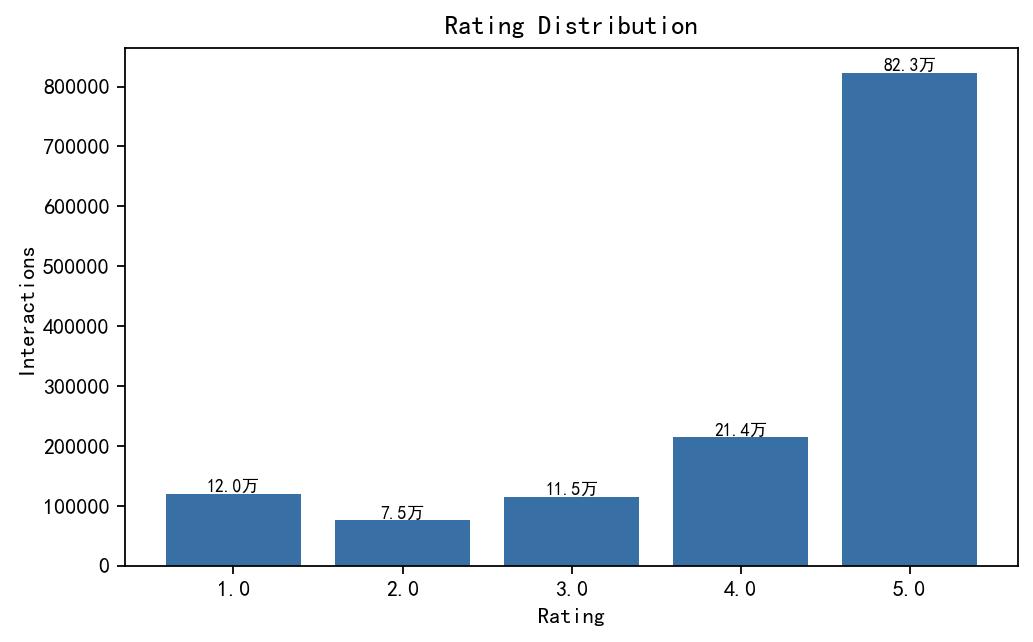

In [9]:
# 08. Rating Distribution

rating_dist = df["Rating"].value_counts().sort_index()

plt.figure(figsize=(7.2, 4.2))

bars = plt.bar(
    rating_dist.index.astype(str),
    rating_dist.values,
    color="#386FA4"
)

plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Interactions")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height()/10000:.1f}万",
        ha="center",
        va="bottom",
        fontsize=8,
    )

plt.show()

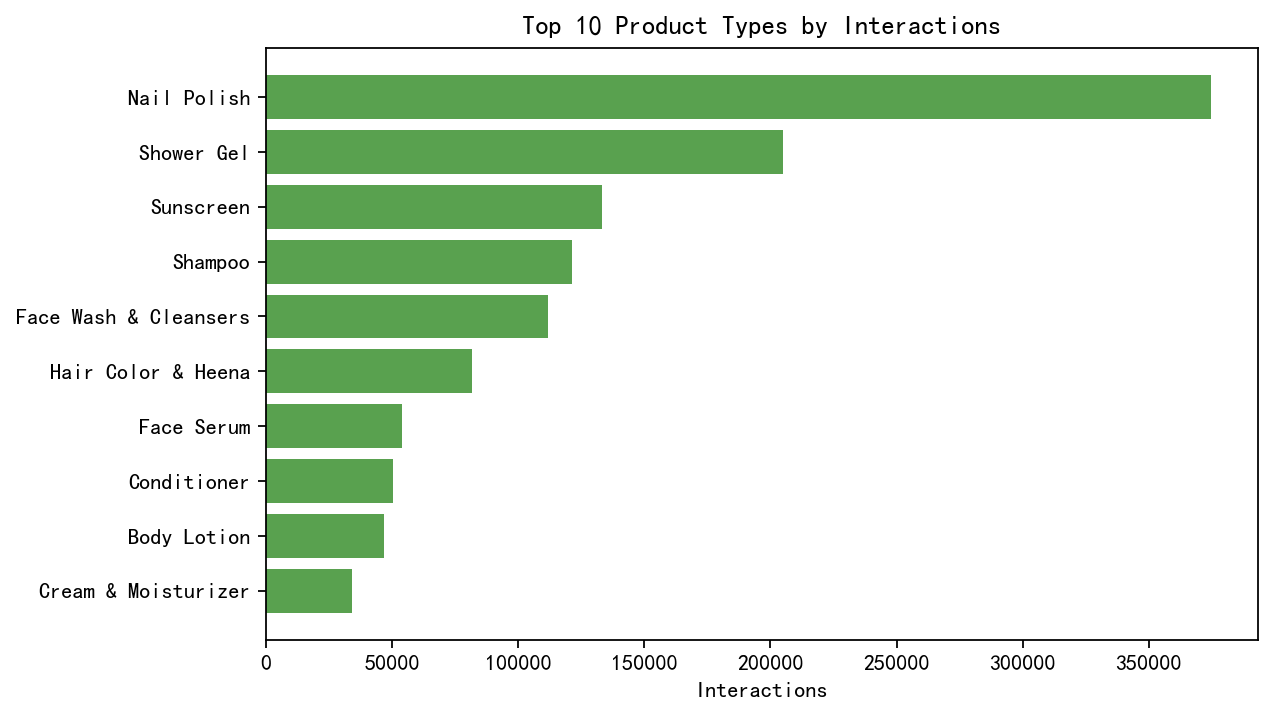

In [10]:
# 09. Top 10 Product Types

top_types = type_counts.head(10).sort_values()

plt.figure(figsize=(8, 4.8))

plt.barh(
    top_types.index.astype(str),
    top_types.values,
    color="#59A14F"
)

plt.title("Top 10 Product Types by Interactions")
plt.xlabel("Interactions")

plt.show()

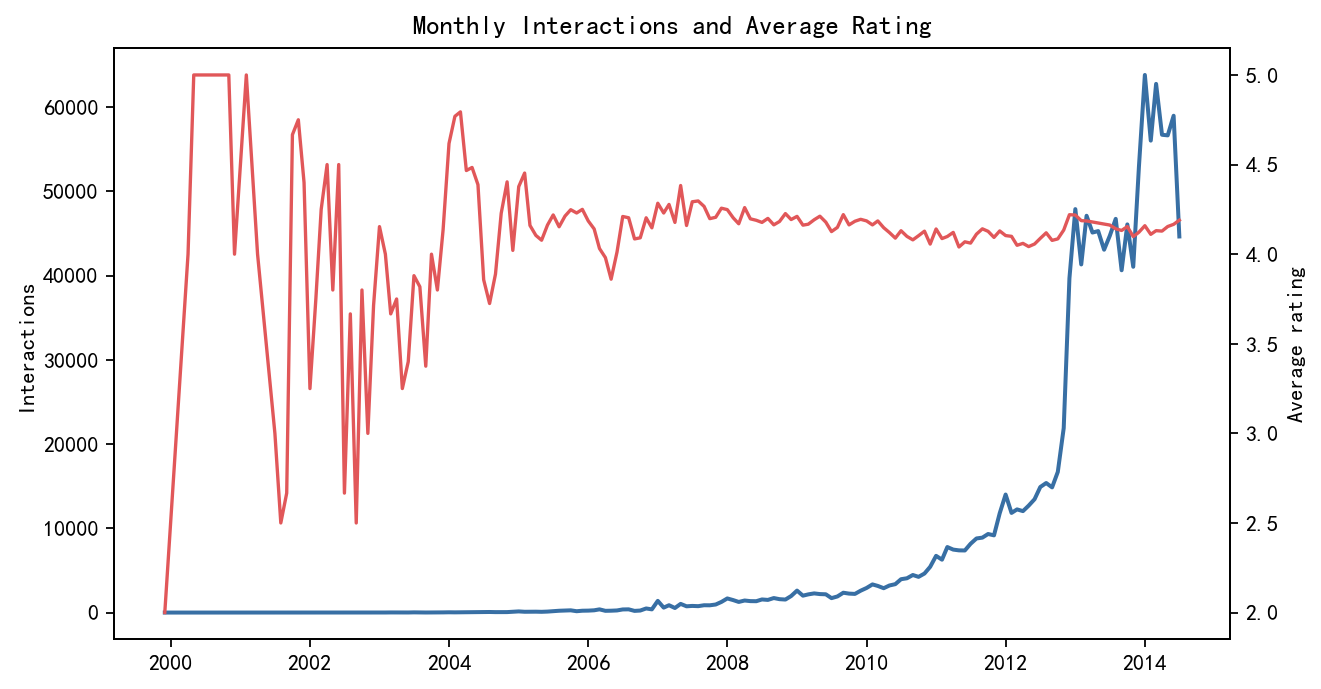

In [11]:
# 10. Monthly Interactions and Average Rating

monthly = (
    df.groupby("year_month")
    .agg(
        interactions=("Rating", "size"),
        avg_rating=("Rating", "mean")
    )
    .reset_index()
)

monthly["date"] = pd.to_datetime(monthly["year_month"] + "-01")

plt.figure(figsize=(9, 4.8))

ax = plt.gca()

ax.plot(
    monthly["date"],
    monthly["interactions"],
    color="#386FA4",
    linewidth=1.8,
    label="Interactions"
)

ax.set_ylabel("Interactions")

ax2 = ax.twinx()

ax2.plot(
    monthly["date"],
    monthly["avg_rating"],
    color="#E15759",
    linewidth=1.5,
    label="Avg rating"
)

ax2.set_ylabel("Average rating")
ax.set_title("Monthly Interactions and Average Rating")

plt.show()

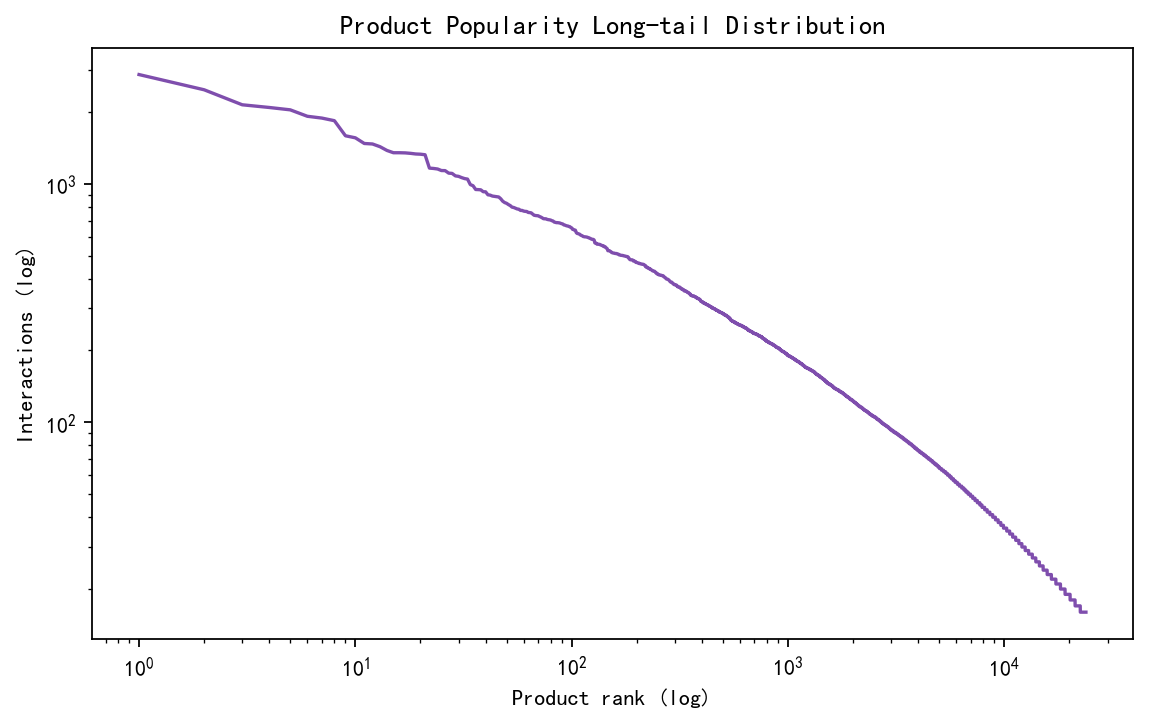

In [12]:
# 11. Product Popularity Long-tail Distribution

sorted_item_counts = np.sort(item_counts.values)[::-1]

plt.figure(figsize=(8.4, 4.8))

plt.loglog(
    np.arange(1, len(sorted_item_counts) + 1),
    sorted_item_counts,
    color="#7F4EAD"
)

plt.title("Product Popularity Long-tail Distribution")
plt.xlabel("Product rank (log)")
plt.ylabel("Interactions (log)")

plt.show()

In [13]:
# 12. Collect EDA Results

eda_results = {
    "overview": overview,
    "user_counts": user_counts,
    "item_counts": item_counts,
    "type_counts": type_counts,
    "monthly": monthly,
}

print("EDA results collected successfully.")

print("Available result keys:")
print(list(eda_results.keys()))

EDA results collected successfully.
Available result keys:
['overview', 'user_counts', 'item_counts', 'type_counts', 'monthly']


In [28]:
# 13. Build Model Dataset

def build_model_dataset(
    df: pd.DataFrame,
    user_min: int = 2,
    item_min: int = 5,
    max_rows: int = 50000
) -> Tuple[pd.DataFrame, Dict]:

    # 1. Remove rows without valid dates
    valid_df = df.loc[df["date"].notna()].copy()

    # 2. Split by cumulative daily interaction counts
    # All records from the same date stay in the same split.
    daily_counts = (
        valid_df.groupby("date")
        .size()
        .sort_index()
    )

    if len(daily_counts) < 3:
        raise ValueError(
            "At least 3 unique dates are required for "
            "train/validation/test splitting."
        )

    cumulative_counts = daily_counts.cumsum()
    total_records = len(valid_df)

    # Find the date boundaries closest to 60% and 80%
    train_end_idx = int(
        np.abs(
            cumulative_counts.values
            - total_records * 0.60
        ).argmin()
    )

    val_end_idx = int(
        np.abs(
            cumulative_counts.values
            - total_records * 0.80
        ).argmin()
    )

    # Ensure that all three splits contain at least one date
    train_end_idx = max(0, train_end_idx)
    val_end_idx = max(train_end_idx + 1, val_end_idx)
    val_end_idx = min(
        val_end_idx,
        len(daily_counts) - 2
    )

    train_date_max = daily_counts.index[train_end_idx]
    val_date_max = daily_counts.index[val_end_idx]

    # 3. Assign chronological splits
    valid_df["split"] = np.select(
        [
            valid_df["date"] <= train_date_max,
            valid_df["date"] <= val_date_max
        ],
        [
            "train",
            "val"
        ],
        default="test"
    )

    # 4. Calculate user/item interaction counts
    # using training data only
    train_raw = valid_df[
        valid_df["split"] == "train"
    ]

    user_counts = train_raw["UserId"].value_counts()
    item_counts = train_raw["ProductId"].value_counts()

    keep_users = user_counts[
        user_counts >= user_min
    ].index

    keep_items = item_counts[
        item_counts >= item_min
    ].index

    # 5. Keep eligible users and items across all splits
    model_df = valid_df[
        valid_df["UserId"].isin(keep_users)
        & valid_df["ProductId"].isin(keep_items)
    ].copy()

    if len(model_df) == 0:
        raise ValueError(
            "No records remain after filtering. "
            "Consider lowering user_min or item_min."
        )

    # 6. Sample within each split proportionally
    if max_rows is not None and len(model_df) > max_rows:

        split_order = ["train", "val", "test"]

        split_sizes = (
            model_df["split"]
            .value_counts()
            .reindex(split_order, fill_value=0)
        )

        raw_quotas = (
            split_sizes / split_sizes.sum() * max_rows
        )

        sample_quotas = np.floor(
            raw_quotas
        ).astype(int)

        remainder = max_rows - int(sample_quotas.sum())

        fractional_parts = (
            raw_quotas - sample_quotas
        ).sort_values(ascending=False)

        for split_name in fractional_parts.index[:remainder]:
            sample_quotas[split_name] += 1

        sampled_parts = []

        for split_name in split_order:
            n_sample = int(sample_quotas[split_name])

            if n_sample > 0:
                split_data = model_df[
                    model_df["split"] == split_name
                ]

                sampled_parts.append(
                    split_data.sample(
                        n=n_sample,
                        random_state=RANDOM_STATE
                    )
                )

        model_df = pd.concat(
            sampled_parts,
            ignore_index=True
        )

    # 7. Sort records chronologically
    model_df = (
        model_df
        .sort_values(["date", "UserId", "ProductId"])
        .reset_index(drop=True)
    )

    # 8. Encode users, items, and product types
    model_df["user_idx"] = (
        pd.Categorical(model_df["UserId"])
        .codes.astype("int32")
    )

    model_df["item_idx"] = (
        pd.Categorical(model_df["ProductId"])
        .codes.astype("int32")
    )

    model_df["type_idx"] = (
        pd.Categorical(model_df["ProductType"])
        .codes.astype("int16")
    )

    # 9. Generate split statistics
    split_stats = {
        "user_min": user_min,
        "item_min": item_min,
        "max_rows": max_rows,

        "records": int(len(model_df)),
        "users": int(model_df["UserId"].nunique()),
        "items": int(model_df["ProductId"].nunique()),
        "types": int(model_df["ProductType"].nunique()),

        "eligible_users": int(len(keep_users)),
        "eligible_items": int(len(keep_items)),

        "train_records": int(
            (model_df["split"] == "train").sum()
        ),
        "val_records": int(
            (model_df["split"] == "val").sum()
        ),
        "test_records": int(
            (model_df["split"] == "test").sum()
        ),

        "train_date_min": model_df.loc[
            model_df["split"] == "train", "date"
        ].min(),

        "train_date_max": model_df.loc[
            model_df["split"] == "train", "date"
        ].max(),

        "val_date_min": model_df.loc[
            model_df["split"] == "val", "date"
        ].min(),

        "val_date_max": model_df.loc[
            model_df["split"] == "val", "date"
        ].max(),

        "test_date_min": model_df.loc[
            model_df["split"] == "test", "date"
        ].min(),

        "test_date_max": model_df.loc[
            model_df["split"] == "test", "date"
        ].max(),
    }

    return model_df, split_stats


print("Model dataset function defined successfully.")

Model dataset function defined successfully.


In [15]:
# 14. Feature Store Definition

@dataclass
class FeatureStore:
    global_mean: float
    global_std: float
    feature_names: List[str]
    user_stats: pd.DataFrame
    item_stats: pd.DataFrame
    cat_stats: pd.DataFrame
    product_type_map: Dict[str, int]


print("FeatureStore class defined successfully.")

FeatureStore class defined successfully.


In [31]:
# 15. Build Feature Store

def make_feature_store(
    train_df: pd.DataFrame,
    all_df: pd.DataFrame
) -> FeatureStore:

    # Global statistics calculated from training data only
    global_mean = float(train_df["Rating"].mean())
    global_std = float(train_df["Rating"].std())

    if pd.isna(global_std):
        global_std = 0.0

    # User-level statistics
    user_stats = train_df.groupby("UserId").agg(
        user_train_count=("Rating", "size"),
        user_train_sum=("Rating", "sum"),
        user_train_sumsq=("Rating", lambda x: (x ** 2).sum()),
        user_train_avg=("Rating", "mean"),
        user_train_std=("Rating", "std"),
        user_category_nunique=("ProductType", "nunique"),
    )

    user_stats["user_train_std"] = (
        user_stats["user_train_std"].fillna(0.0)
    )

    # Item-level statistics
    item_stats = train_df.groupby("ProductId").agg(
        item_train_count=("Rating", "size"),
        item_train_sum=("Rating", "sum"),
        item_train_sumsq=("Rating", lambda x: (x ** 2).sum()),
        item_train_avg=("Rating", "mean"),
        item_train_std=("Rating", "std"),
        item_category=("ProductType", "first"),
    )

    item_stats["item_train_std"] = (
        item_stats["item_train_std"].fillna(0.0)
    )

    # Product-category statistics
    cat_stats = train_df.groupby("ProductType").agg(
        category_train_count=("Rating", "size"),
        category_train_sum=("Rating", "sum"),
        category_train_avg=("Rating", "mean"),
    )

    # Create product type mapping
    all_types = sorted(
        all_df["ProductType"].dropna().unique().tolist()
    )

    product_type_map = {
        ptype: idx
        for idx, ptype in enumerate(all_types)
    }

    feature_names = [
        "user_count_log",
        "user_avg_rating",
        "user_rating_std",
        "user_category_diversity",
        "item_count_log",
        "item_avg_rating",
        "item_rating_std",
        "category_count_log",
        "category_avg_rating",
        "type_idx",
        "year",
        "month",
        "quarter",
    ]

    return FeatureStore(
        global_mean=global_mean,
        global_std=global_std,
        feature_names=feature_names,
        user_stats=user_stats,
        item_stats=item_stats,
        cat_stats=cat_stats,
        product_type_map=product_type_map,
    )


print("Feature store function defined successfully.")

Feature store function defined successfully.


In [57]:
# 16. Apply Strictly Historical Features
#
# Train:
#   Use interactions strictly earlier than the current date.
#   Same-day interactions are excluded.
#
# Validation / Test:
#   Use full training-set statistics.
#   Cold-start entities fall back to training global statistics.
#
# Fixes:
#   1. Numerically stable variance calculation using centered ratings.
#   2. Cumulative user category diversity with strict date exclusion.

import numpy as np
import pandas as pd


def apply_features(model_df, store):

    # =========================================================
    # 1. Prepare data
    # =========================================================

    out = model_df.copy().reset_index(drop=True)
    out["_row_id"] = np.arange(len(out))

    train_mask = out["split"].eq("train")
    train_part = out.loc[train_mask].copy()

    if train_part.empty:
        raise ValueError("No training rows found.")

    train_part["Rating"] = pd.to_numeric(
        train_part["Rating"], errors="raise"
    ).astype("float64")

    # Center ratings to improve numerical stability.
    RATING_CENTER = 3.0
    train_part["_rating_centered"] = (
        train_part["Rating"] - RATING_CENTER
    )

    # =========================================================
    # 2. Prepare full-training FeatureStore statistics
    # =========================================================

    user_stats = store.user_stats.reset_index().copy()
    item_stats = store.item_stats.reset_index().copy()
    cat_stats = store.cat_stats.reset_index().copy()

    user_features = user_stats[
        [
            "UserId",
            "user_train_count",
            "user_train_avg",
            "user_train_std",
            "user_category_nunique"
        ]
    ].rename(
        columns={
            "user_train_avg": "user_avg_rating",
            "user_train_std": "user_rating_std",
            "user_category_nunique": "user_category_diversity"
        }
    )

    item_features = item_stats[
        [
            "ProductId",
            "item_train_count",
            "item_train_avg",
            "item_train_std"
        ]
    ].rename(
        columns={
            "item_train_avg": "item_avg_rating",
            "item_train_std": "item_rating_std"
        }
    )

    category_features = cat_stats[
        [
            "ProductType",
            "category_train_count",
            "category_train_avg"
        ]
    ].rename(
        columns={
            "category_train_avg": "category_avg_rating"
        }
    )

    out = out.merge(
        user_features,
        on="UserId",
        how="left",
        validate="many_to_one"
    )

    out = out.merge(
        item_features,
        on="ProductId",
        how="left",
        validate="many_to_one"
    )

    out = out.merge(
        category_features,
        on="ProductType",
        how="left",
        validate="many_to_one"
    )

    if len(out) != len(model_df):
        raise ValueError("FeatureStore merge changed row count.")

    out = out.sort_values("_row_id").reset_index(drop=True)

    # =========================================================
    # 3. Build strictly historical entity statistics
    # =========================================================

    def build_historical_stats(data, entity_col, prefix):

        daily = (
            data.groupby(
                [entity_col, "date"],
                observed=True
            )
            .agg(
                daily_count=("Rating", "count"),
                daily_sum=("Rating", "sum"),
                daily_centered_sum=("_rating_centered", "sum"),
                daily_centered_sumsq=(
                    "_rating_centered",
                    lambda x: np.square(
                        x.to_numpy(dtype="float64")
                    ).sum(dtype="float64")
                )
            )
            .reset_index()
            .sort_values([entity_col, "date"])
        )

        for col in [
            "daily_sum",
            "daily_centered_sum",
            "daily_centered_sumsq"
        ]:
            daily[col] = daily[col].astype("float64")

        grouped = daily.groupby(entity_col, sort=False)

        daily["cum_count"] = grouped["daily_count"].cumsum()
        daily["cum_sum"] = grouped["daily_sum"].cumsum()
        daily["cum_centered_sum"] = (
            grouped["daily_centered_sum"].cumsum()
        )
        daily["cum_centered_sumsq"] = (
            grouped["daily_centered_sumsq"].cumsum()
        )

        # Exclude all interactions on the current date.
        daily["hist_count"] = (
            daily["cum_count"] - daily["daily_count"]
        )

        daily["hist_sum"] = (
            daily["cum_sum"] - daily["daily_sum"]
        )

        daily["hist_centered_sum"] = (
            daily["cum_centered_sum"]
            - daily["daily_centered_sum"]
        )

        daily["hist_centered_sumsq"] = (
            daily["cum_centered_sumsq"]
            - daily["daily_centered_sumsq"]
        )

        denominator = daily["hist_count"].replace(0, np.nan)

        daily["hist_avg"] = (
            daily["hist_sum"] / denominator
        )

        variance_numerator = (
            daily["hist_centered_sumsq"]
            - daily["hist_centered_sum"].pow(2) / denominator
        )

        variance = (
            variance_numerator
            / (daily["hist_count"] - 1).replace(0, np.nan)
        )

        daily["hist_std"] = np.sqrt(
            variance.clip(lower=0)
        )

        return daily[
            [
                entity_col,
                "date",
                "hist_count",
                "hist_avg",
                "hist_std"
            ]
        ].rename(
            columns={
                "hist_count": f"{prefix}_hist_count",
                "hist_avg": f"{prefix}_hist_avg",
                "hist_std": f"{prefix}_hist_std"
            }
        )

    user_history = build_historical_stats(
        train_part, "UserId", "user"
    )

    item_history = build_historical_stats(
        train_part, "ProductId", "item"
    )

    category_history = build_historical_stats(
        train_part, "ProductType", "category"
    )

    # =========================================================
    # 4. Build strictly historical global statistics
    # =========================================================

    global_daily = (
        train_part.groupby("date")
        .agg(
            daily_count=("Rating", "count"),
            daily_sum=("Rating", "sum"),
            daily_centered_sum=("_rating_centered", "sum"),
            daily_centered_sumsq=(
                "_rating_centered",
                lambda x: np.square(
                    x.to_numpy(dtype="float64")
                ).sum(dtype="float64")
            )
        )
        .reset_index()
        .sort_values("date")
    )

    for col in [
        "daily_sum",
        "daily_centered_sum",
        "daily_centered_sumsq"
    ]:
        global_daily[col] = global_daily[col].astype("float64")

    global_daily["cum_count"] = (
        global_daily["daily_count"].cumsum()
    )

    global_daily["cum_sum"] = (
        global_daily["daily_sum"].cumsum()
    )

    global_daily["cum_centered_sum"] = (
        global_daily["daily_centered_sum"].cumsum()
    )

    global_daily["cum_centered_sumsq"] = (
        global_daily["daily_centered_sumsq"].cumsum()
    )

    # Exclude all interactions on the current date.
    global_daily["hist_count"] = (
        global_daily["cum_count"] - global_daily["daily_count"]
    )

    global_daily["hist_sum"] = (
        global_daily["cum_sum"] - global_daily["daily_sum"]
    )

    global_daily["hist_centered_sum"] = (
        global_daily["cum_centered_sum"]
        - global_daily["daily_centered_sum"]
    )

    global_daily["hist_centered_sumsq"] = (
        global_daily["cum_centered_sumsq"]
        - global_daily["daily_centered_sumsq"]
    )

    denominator = global_daily["hist_count"].replace(0, np.nan)

    global_daily["global_hist_avg"] = (
        global_daily["hist_sum"] / denominator
    )

    variance_numerator = (
        global_daily["hist_centered_sumsq"]
        - global_daily["hist_centered_sum"].pow(2) / denominator
    )

    variance = (
        variance_numerator
        / (global_daily["hist_count"] - 1).replace(0, np.nan)
    )

    global_daily["global_hist_std"] = np.sqrt(
        variance.clip(lower=0)
    )

    global_history = global_daily[
        ["date", "global_hist_avg", "global_hist_std"]
    ].copy()

    # =========================================================
    # 5. Merge historical statistics for training rows
    # =========================================================

    train_history = train_part[
        ["_row_id", "UserId", "ProductId", "ProductType", "date"]
    ].copy()

    train_history = train_history.merge(
        user_history,
        on=["UserId", "date"],
        how="left",
        validate="many_to_one"
    )

    train_history = train_history.merge(
        item_history,
        on=["ProductId", "date"],
        how="left",
        validate="many_to_one"
    )

    train_history = train_history.merge(
        category_history,
        on=["ProductType", "date"],
        how="left",
        validate="many_to_one"
    )

    train_history = train_history.merge(
        global_history,
        on="date",
        how="left",
        validate="many_to_one"
    )

    # =========================================================
    # 6. Build cumulative historical user category diversity
    # =========================================================

    first_seen = (
        train_part.groupby(
            ["UserId", "ProductType"],
            observed=True
        )["date"]
        .min()
        .reset_index(name="first_seen_date")
    )

    new_categories = (
        first_seen.groupby(
            ["UserId", "first_seen_date"],
            observed=True
        )
        .size()
        .reset_index(name="new_category_count")
        .sort_values(["first_seen_date", "UserId"])
    )

    new_categories["cum_categories"] = (
        new_categories.groupby(
            "UserId", sort=False
        )["new_category_count"].cumsum()
    )

    # Use the cumulative count AFTER each category event.
    # The event itself will be excluded from same-day records
    # by allow_exact_matches=False below.
    left_sorted = train_history.sort_values(
        ["date", "UserId", "_row_id"]
    ).copy()

    right_sorted = new_categories[
        ["UserId", "first_seen_date", "cum_categories"]
    ].sort_values(
        ["first_seen_date", "UserId"]
    ).copy()

    train_history = pd.merge_asof(
        left_sorted,
        right_sorted,
        left_on="date",
        right_on="first_seen_date",
        by="UserId",
        direction="backward",
        allow_exact_matches=False
    )

    train_history["cum_categories"] = (
        train_history["cum_categories"].fillna(0)
    )

    train_history = (
        train_history
        .rename(
            columns={
                "cum_categories": "hist_category_diversity"
            }
        )
        .drop(columns=["first_seen_date", "new_category_count"],
              errors="ignore")
        .set_index("_row_id")
        .sort_index()
    )

    # =========================================================
    # 7. Replace training features with historical values
    # =========================================================

    train_row_ids = out.loc[
        train_mask, "_row_id"
    ].to_numpy()

    historical_columns = {
        "user_train_count": "user_hist_count",
        "user_avg_rating": "user_hist_avg",
        "user_rating_std": "user_hist_std",
        "user_category_diversity": "hist_category_diversity",

        "item_train_count": "item_hist_count",
        "item_avg_rating": "item_hist_avg",
        "item_rating_std": "item_hist_std",

        "category_train_count": "category_hist_count",
        "category_avg_rating": "category_hist_avg"
    }

    for output_col, history_col in historical_columns.items():

        values = train_history.loc[
            train_row_ids, history_col
        ].to_numpy(dtype="float64", na_value=np.nan)

        out[output_col] = pd.to_numeric(
            out[output_col], errors="coerce"
        ).astype("float64")

        out.loc[train_mask, output_col] = values

    # =========================================================
    # 8. Fill missing training averages/stds with historical
    #    global statistics
    # =========================================================

    global_mean_hist = train_history.loc[
        train_row_ids, "global_hist_avg"
    ].to_numpy(dtype="float64", na_value=np.nan)

    global_std_hist = train_history.loc[
        train_row_ids, "global_hist_std"
    ].to_numpy(dtype="float64", na_value=np.nan)

    global_mean_hist = np.where(
        np.isnan(global_mean_hist), 3.0, global_mean_hist
    )

    global_std_hist = np.where(
        np.isnan(global_std_hist), 0.0, global_std_hist
    )

    for col in [
        "user_avg_rating",
        "item_avg_rating",
        "category_avg_rating"
    ]:

        values = out.loc[
            train_mask, col
        ].to_numpy(dtype="float64")

        out.loc[train_mask, col] = np.where(
            np.isnan(values), global_mean_hist, values
        )

    for col in ["user_rating_std", "item_rating_std"]:

        values = out.loc[
            train_mask, col
        ].to_numpy(dtype="float64")

        out.loc[train_mask, col] = np.where(
            np.isnan(values), global_std_hist, values
        )

    # =========================================================
    # 9. Fill Validation/Test cold-start features
    # =========================================================

    training_global_mean = float(store.global_mean)
    training_global_std = float(store.global_std)

    non_train_mask = ~train_mask

    for col in [
        "user_avg_rating",
        "item_avg_rating",
        "category_avg_rating"
    ]:

        out.loc[non_train_mask, col] = (
            out.loc[non_train_mask, col]
            .fillna(training_global_mean)
        )

    for col in ["user_rating_std", "item_rating_std"]:

        out.loc[non_train_mask, col] = (
            out.loc[non_train_mask, col]
            .fillna(training_global_std)
        )

    # =========================================================
    # 10. Fill missing counts and diversity
    # =========================================================

    count_columns = [
        "user_train_count",
        "item_train_count",
        "category_train_count"
    ]

    for col in count_columns:

        out[col] = (
            pd.to_numeric(out[col], errors="coerce")
            .fillna(0)
            .clip(lower=0)
        )

    out["user_category_diversity"] = (
        pd.to_numeric(
            out["user_category_diversity"],
            errors="coerce"
        )
        .fillna(0)
        .clip(lower=0)
    )

    # =========================================================
    # 11. Log-transform count features
    # =========================================================

    for col in count_columns:
        out[f"{col}_log"] = np.log1p(out[col])

    # =========================================================
    # 12. Product type index
    # =========================================================

    out["type_idx"] = (
        out["ProductType"]
        .map(store.product_type_map)
        .fillna(-1)
        .astype("int32")
    )

    # =========================================================
    # 13. Restore order
    # =========================================================

    out = (
        out.sort_values("_row_id")
        .drop(columns=["_row_id"])
        .reset_index(drop=True)
    )

    # =========================================================
    # 14. Final validation
    # =========================================================

    model_feature_columns = [
        "user_train_count",
        "user_avg_rating",
        "user_rating_std",
        "user_category_diversity",
        "item_train_count",
        "item_avg_rating",
        "item_rating_std",
        "category_train_count",
        "category_avg_rating"
    ]

    missing_summary = out[model_feature_columns].isna().sum()

    if missing_summary.any():
        raise ValueError(
            "Missing values remain in model features:\n"
            f"{missing_summary[missing_summary > 0]}"
        )

    if len(out) != len(model_df):
        raise ValueError("Final row count mismatch.")

    return out


print("Strictly historical feature application function defined successfully.")

Strictly historical feature application function defined successfully.


In [18]:
# 17. User Behavior Feature Preparation

def prepare_user_features(
    model_df: pd.DataFrame
) -> pd.DataFrame:

    user_features = model_df.groupby("UserId").agg(
        rating_count=("Rating", "size"),
        avg_rating=("Rating", "mean"),
        rating_std=("Rating", "std"),
        unique_items=("ProductId", "nunique"),
        category_diversity=("ProductType", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max"),
    )

    user_features["rating_std"] = (
        user_features["rating_std"].fillna(0.0)
    )

    user_features["active_span_days"] = (
        user_features["last_date"]
        - user_features["first_date"]
    ).dt.days.clip(lower=0)

    user_features["log_count"] = np.log1p(
        user_features["rating_count"]
    )

    user_features["log_span"] = np.log1p(
        user_features["active_span_days"]
    )

    return user_features


print("User behavior feature function defined successfully.")

User behavior feature function defined successfully.


In [19]:
# 18. K-Means Clustering & PCA Visualization

def perform_user_clustering(
    user_features: pd.DataFrame
) -> Tuple[pd.DataFrame, StandardScaler, KMeans, PCA]:

    cluster_cols = [
        "log_count",
        "avg_rating",
        "rating_std",
        "category_diversity",
        "log_span"
    ]

    scaler = StandardScaler()

    X_cluster = scaler.fit_transform(
        user_features[cluster_cols]
    )

    kmeans = KMeans(
        n_clusters=4,
        random_state=RANDOM_STATE,
        n_init=20
    )

    user_features = user_features.copy()

    user_features["cluster"] = (
        kmeans.fit_predict(X_cluster)
    )

    pca = PCA(
        n_components=2,
        random_state=RANDOM_STATE
    )

    pcs = pca.fit_transform(X_cluster)

    user_features["pc1"] = pcs[:, 0]
    user_features["pc2"] = pcs[:, 1]

    # User segmentation PCA plot
    plt.figure(figsize=(7.4, 5.2))

    sample_users = user_features.sample(
        min(6000, len(user_features)),
        random_state=RANDOM_STATE
    )

    scatter = plt.scatter(
        sample_users["pc1"],
        sample_users["pc2"],
        c=sample_users["cluster"],
        cmap="tab10",
        s=8,
        alpha=0.55
    )

    plt.title("K-Means User Segments (PCA Projection)")
    plt.xlabel("PC1")
    plt.ylabel("PC2")

    plt.colorbar(
        scatter,
        label="Cluster"
    )

    plt.show()

    return user_features, scaler, kmeans, pca


print("User clustering function defined successfully.")

User clustering function defined successfully.


In [21]:
# 19. Correlation Heatmap

def plot_correlation_heatmap(
    feature_df: pd.DataFrame
) -> pd.DataFrame:

    corr_cols = [
        "Rating",
        "user_count_log",
        "user_avg_rating",
        "item_count_log",
        "item_avg_rating",
        "category_avg_rating",
        "type_idx",
        "month",
    ]

    corr = feature_df[corr_cols].corr(
        numeric_only=True
    )

    plt.figure(figsize=(7.6, 6.0))

    im = plt.imshow(
        corr,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1
    )

    plt.xticks(
        range(len(corr_cols)),
        corr_cols,
        rotation=45,
        ha="right",
        fontsize=8
    )

    plt.yticks(
        range(len(corr_cols)),
        corr_cols,
        fontsize=8
    )

    plt.colorbar(
        im,
        fraction=0.046,
        pad=0.04
    )

    plt.title("Correlation Heatmap")

    for i in range(len(corr_cols)):
        for j in range(len(corr_cols)):
            plt.text(
                j,
                i,
                f"{corr.iloc[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=6
            )

    plt.show()

    return corr


print("Correlation heatmap function defined successfully.")

Correlation heatmap function defined successfully.


In [58]:
# 20. Execute Model Dataset & Feature Engineering

# Build the complete model dataset without random sampling
model_df, split_stats = build_model_dataset(
    df,
    user_min=2,
    item_min=5,
    max_rows=None
)

# Separate training, validation, and test data
train_df = model_df[
    model_df["split"] == "train"
].copy()

val_df = model_df[
    model_df["split"] == "val"
].copy()

test_df = model_df[
    model_df["split"] == "test"
].copy()

print("Model dataset created successfully.")
print("\nSplit statistics:")

for key, value in split_stats.items():
    print(f"{key}: {value}")


# Build feature store using training data only
feature_store = make_feature_store(
    train_df,
    model_df
)


# Apply training-derived features to all splits
feature_df = apply_features(
    model_df,
    feature_store
)


print("\nFeature engineering completed.")
print("Feature dataset shape:", feature_df.shape)

print("\nMissing values in feature dataset:")
print(
    feature_df
    .isna()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Model dataset created successfully.

Split statistics:
user_min: 2
item_min: 5
max_rows: None
records: 413763
users: 115002
items: 21879
types: 19
eligible_users: 115009
eligible_items: 21967
train_records: 365975
val_records: 28821
test_records: 18967
train_date_min: 2000-12-19 00:00:00
train_date_max: 2013-09-30 00:00:00
val_date_min: 2013-10-01 00:00:00
val_date_max: 2014-03-05 00:00:00
test_date_min: 2014-03-06 00:00:00
test_date_max: 2014-07-22 00:00:00

Feature engineering completed.
Feature dataset shape: (413763, 27)

Missing values in feature dataset:
UserId         0
ProductId      0
ProductType    0
Rating         0
Timestamp      0
date           0
year           0
month          0
quarter        0
year_month     0
dtype: int64


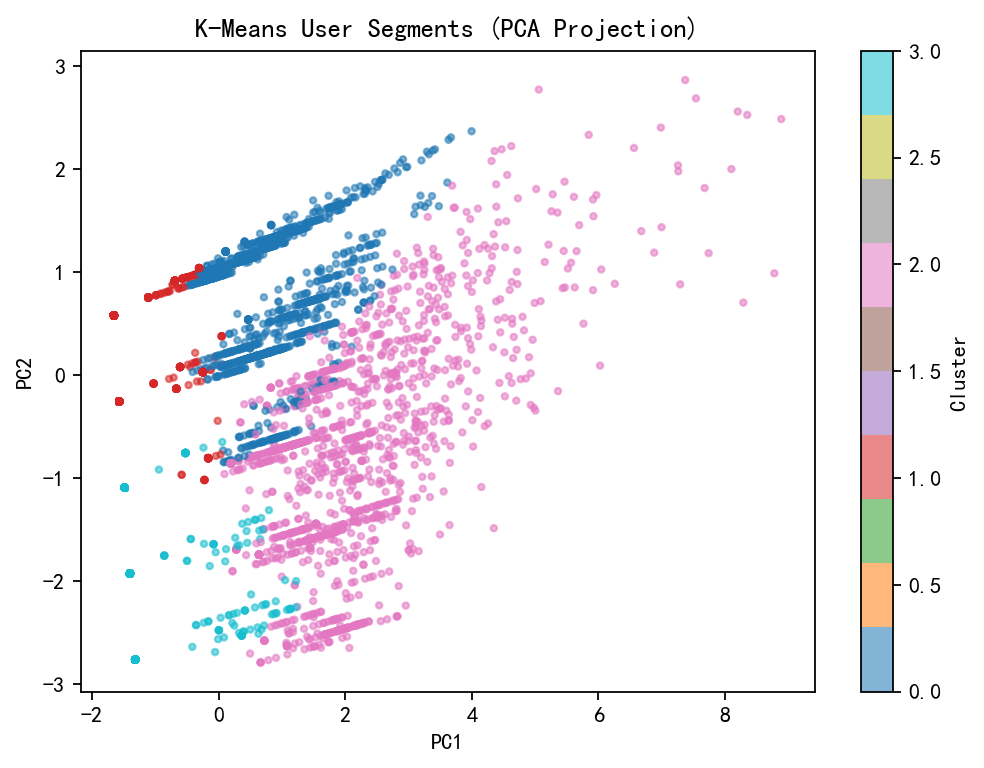

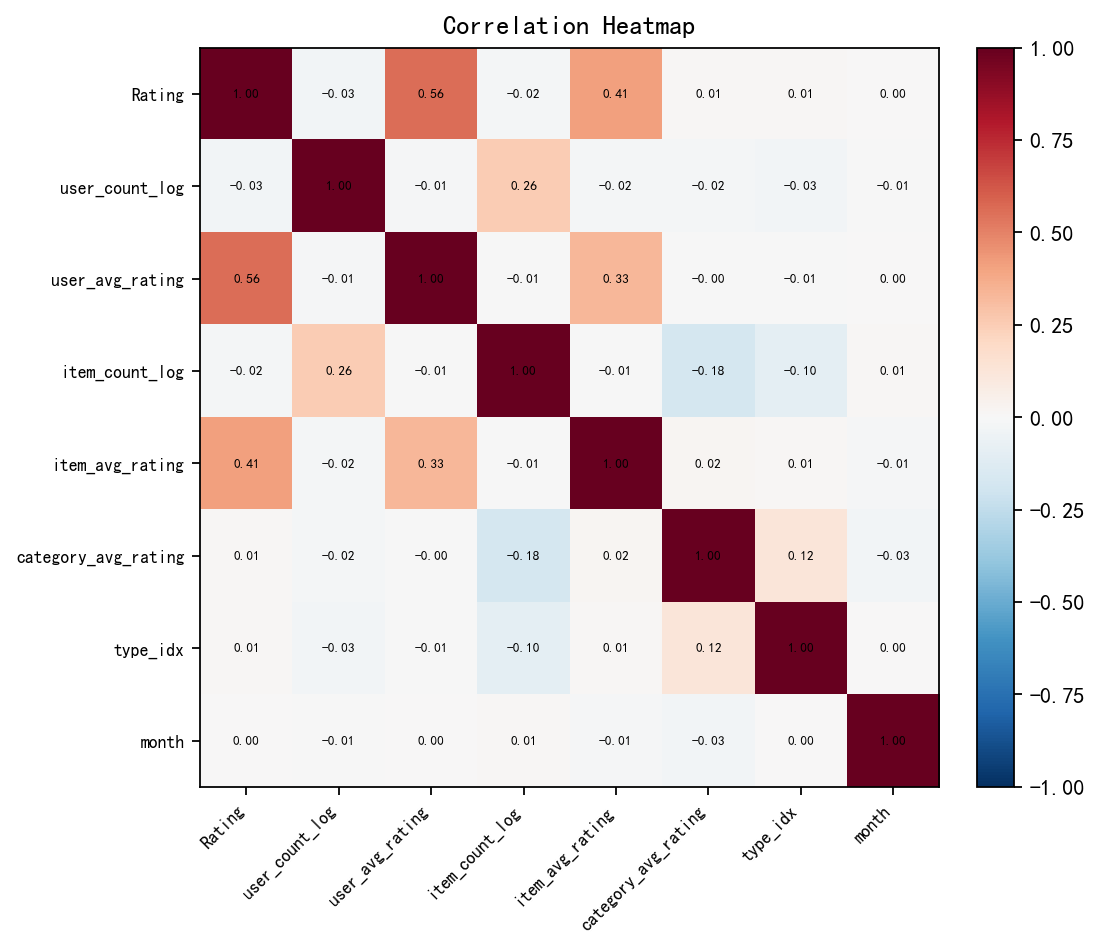

Exploratory analysis completed.

Cluster distribution:
cluster
0    5762
1    8753
2    5191
3    2443
Name: count, dtype: int64

PCA explained variance ratio:
[0.56760483 0.23599201]


In [23]:
# 21. Execute Exploratory Analysis

user_features = prepare_user_features(model_df)

user_features, scaler, kmeans, pca = perform_user_clustering(
    user_features
)

corr = plot_correlation_heatmap(feature_df)

print("Exploratory analysis completed.")
print("\nCluster distribution:")
print(user_features["cluster"].value_counts().sort_index())

print("\nPCA explained variance ratio:")
print(pca.explained_variance_ratio_)

In [24]:
# 22. Data Leakage & Feature Quality Diagnostics

# 1. Check missing values in actual engineered features
model_feature_cols = [
    "user_count_log",
    "user_avg_rating",
    "user_rating_std",
    "user_category_diversity",
    "item_count_log",
    "item_avg_rating",
    "item_rating_std",
    "category_count_log",
    "category_avg_rating",
    "type_idx",
    "year",
    "month",
    "quarter",
]

print("=== 1. Missing Values in Model Features ===")
print(
    feature_df[model_feature_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

# 2. Check whether the same date appears in multiple splits
print("\n=== 2. Date Overlap Between Splits ===")

date_split_counts = (
    model_df.groupby("date")["split"]
    .nunique()
)

print(
    "Dates appearing in multiple splits:",
    int((date_split_counts > 1).sum())
)

# 3. Check whether user and item statistics include
# the current training interaction
print("\n=== 3. Training Feature Statistics ===")

train_feature_check = feature_df[
    feature_df["split"] == "train"
]

print(
    "Training rows:",
    len(train_feature_check)
)

print(
    "Training rows with missing user average:",
    int(train_feature_check["user_avg_rating"].isna().sum())
)

print(
    "Training rows with missing item average:",
    int(train_feature_check["item_avg_rating"].isna().sum())
)

# 4. Check interaction counts in the model dataset
print("\n=== 4. Model Dataset Interaction Counts ===")

print(
    "Minimum user interactions:",
    model_df["UserId"].value_counts().min()
)

print(
    "Minimum item interactions:",
    model_df["ProductId"].value_counts().min()
)

print(
    "Maximum user interactions:",
    model_df["UserId"].value_counts().max()
)

print(
    "Maximum item interactions:",
    model_df["ProductId"].value_counts().max()
)

=== 1. Missing Values in Model Features ===
user_count_log             0
user_avg_rating            0
user_rating_std            0
user_category_diversity    0
item_count_log             0
item_avg_rating            0
item_rating_std            0
category_count_log         0
category_avg_rating        0
type_idx                   0
year                       0
month                      0
quarter                    0
dtype: int64

=== 2. Date Overlap Between Splits ===
Dates appearing in multiple splits: 1

=== 3. Training Feature Statistics ===
Training rows: 30000
Training rows with missing user average: 0
Training rows with missing item average: 0

=== 4. Model Dataset Interaction Counts ===
Minimum user interactions: 1
Minimum item interactions: 1
Maximum user interactions: 44
Maximum item interactions: 112


In [30]:
# 23. Filtering Threshold Sensitivity Analysis (Diagnostic Only)

train_raw = model_df[
    model_df["split"] == "train"
].copy()

# Note:
# Use the current model_df only for checking its existing
# training distribution. We will use the original df to
# evaluate alternative thresholds.

# Recreate chronological split using the same date boundaries
# already established by the current Cell 13.

valid_df = df.loc[df["date"].notna()].copy()

unique_dates = pd.Index(
    valid_df["date"].unique()
).sort_values()

n_dates = len(unique_dates)

train_end_idx = max(1, int(n_dates * 0.60))
val_end_idx = max(
    train_end_idx + 1,
    int(n_dates * 0.80)
)
val_end_idx = min(val_end_idx, n_dates - 1)

train_date_max = unique_dates[train_end_idx - 1]
val_date_max = unique_dates[val_end_idx - 1]

valid_df["split"] = np.select(
    [
        valid_df["date"] <= train_date_max,
        valid_df["date"] <= val_date_max
    ],
    ["train", "val"],
    default="test"
)

train_raw = valid_df[
    valid_df["split"] == "train"
]

user_counts = train_raw["UserId"].value_counts()
item_counts = train_raw["ProductId"].value_counts()

user_thresholds = [1, 2, 3, 5]
item_thresholds = [5, 10, 15, 20, 30]

results = []

for u_min in user_thresholds:
    keep_users = user_counts[
        user_counts >= u_min
    ].index

    for i_min in item_thresholds:
        keep_items = item_counts[
            item_counts >= i_min
        ].index

        filtered = valid_df[
            valid_df["UserId"].isin(keep_users)
            & valid_df["ProductId"].isin(keep_items)
        ]

        results.append({
            "user_min": u_min,
            "item_min": i_min,
            "records": len(filtered),
            "users": filtered["UserId"].nunique(),
            "items": filtered["ProductId"].nunique(),
            "train": int((filtered["split"] == "train").sum()),
            "val": int((filtered["split"] == "val").sum()),
            "test": int((filtered["split"] == "test").sum()),
            "types": filtered["ProductType"].nunique()
        })

threshold_report = pd.DataFrame(results)

print("=== Threshold Sensitivity Analysis ===")
print(
    threshold_report.to_string(index=False)
)

=== Threshold Sensitivity Analysis ===
 user_min  item_min  records  users  items  train  val  test  types
        1         5    67823  51497   3656  59636 3992  4195     13
        1        10    52709  42080   1787  47381 2712  2616      8
        1        15    43038  35324   1083  39103 2057  1878      7
        1        20    36143  30252    730  33138 1634  1371      6
        1        30    27401  23304    401  25335 1149   917      6
        2         5    17738   6022   3305  14793 1588  1357     13
        2        10    13546   5477   1712  11689 1071   786      8
        2        15    11060   4949   1071   9709  816   535      7
        2        20     9294   4473    722   8258  651   385      6
        2        30     7200   3688    400   6501  455   244      6
        3         5     9298   1922   2606   7646  926   726     11
        3        10     7162   1837   1447   6140  615   407      8
        3        15     5955   1745    929   5208  469   278      7
        3

In [59]:
# 24. Historical Feature Validation & Leakage Diagnostics

import numpy as np
import pandas as pd


# =========================================================
# 1. Define model feature columns
# =========================================================

model_feature_cols = [
    "user_train_count",
    "user_avg_rating",
    "user_rating_std",
    "user_category_diversity",

    "item_train_count",
    "item_avg_rating",
    "item_rating_std",

    "category_train_count",
    "category_avg_rating",

    "user_train_count_log",
    "item_train_count_log",
    "category_train_count_log",

    "type_idx"
]

missing_cols = [
    col for col in model_feature_cols
    if col not in feature_df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing expected model features: {missing_cols}"
    )


# =========================================================
# 2. Missing values in model features
# =========================================================

print("=" * 65)
print("1. MISSING VALUES IN MODEL FEATURES")
print("=" * 65)

feature_missing = feature_df[model_feature_cols].isna().sum()

print(feature_missing)

print(
    "\nTotal missing model-feature values:",
    int(feature_missing.sum())
)


# =========================================================
# 3. Feature completeness by split
# =========================================================

print("\n" + "=" * 65)
print("2. FEATURE COMPLETENESS BY DATA SPLIT")
print("=" * 65)

for split_name in ["train", "val", "test"]:

    subset = feature_df[
        feature_df["split"] == split_name
    ]

    missing_total = int(
        subset[model_feature_cols].isna().sum().sum()
    )

    print(
        f"{split_name.upper():5s} | "
        f"records: {len(subset):,} | "
        f"missing feature values: {missing_total}"
    )


# =========================================================
# 4. Training feature summary
# =========================================================

print("\n" + "=" * 65)
print("3. TRAINING FEATURE SUMMARY")
print("=" * 65)

train_features = feature_df[
    feature_df["split"] == "train"
]

summary_cols = [
    "user_train_count",
    "user_avg_rating",
    "user_rating_std",
    "user_category_diversity",
    "item_train_count",
    "item_avg_rating",
    "item_rating_std",
    "category_train_count",
    "category_avg_rating"
]

print(
    train_features[summary_cols].describe().round(4)
)


# =========================================================
# 5. Historical count diagnostics
# =========================================================

print("\n" + "=" * 65)
print("4. HISTORICAL COUNT DIAGNOSTICS")
print("=" * 65)

for col in [
    "user_train_count",
    "item_train_count",
    "category_train_count"
]:

    zero_count = int(
        (train_features[col] == 0).sum()
    )

    print(
        f"{col}: "
        f"zero-history rows = {zero_count:,} "
        f"({zero_count / len(train_features):.2%})"
    )

print(
    "\nNote: Zero historical counts are valid. "
    "They mean the user/item/category had no earlier "
    "training interaction before that record's date."
)


# =========================================================
# 6. Rating range checks
# =========================================================

print("\n" + "=" * 65)
print("5. RATING FEATURE RANGE CHECK")
print("=" * 65)

rating_feature_cols = [
    "user_avg_rating",
    "item_avg_rating",
    "category_avg_rating"
]

for col in rating_feature_cols:

    print(
        f"{col}: "
        f"min = {train_features[col].min():.4f}, "
        f"max = {train_features[col].max():.4f}"
    )

    if (
        train_features[col].min() < 1
        or train_features[col].max() > 5
    ):
        print("WARNING: Values outside the expected rating range!")


# =========================================================
# 7. Log transformation consistency
# =========================================================

print("\n" + "=" * 65)
print("6. LOG TRANSFORMATION CHECK")
print("=" * 65)

log_checks = {
    "user_train_count_log": "user_train_count",
    "item_train_count_log": "item_train_count",
    "category_train_count_log": "category_train_count"
}

for log_col, raw_col in log_checks.items():

    expected = np.log1p(feature_df[raw_col])

    max_error = np.max(
        np.abs(
            feature_df[log_col].to_numpy()
            - expected.to_numpy()
        )
    )

    print(
        f"{log_col}: maximum absolute error = {max_error:.12f}"
    )


# =========================================================
# 8. Strict historical leakage audit
#
# Randomly sample training rows and independently calculate
# the statistics using only dates strictly before each row.
# =========================================================

print("\n" + "=" * 65)
print("7. STRICT HISTORICAL LEAKAGE AUDIT")
print("=" * 65)

audit_source = train_df.copy()

audit_features = feature_df[
    feature_df["split"] == "train"
].copy()

# Sample up to 30 training rows.
audit_sample = audit_features.sample(
    n=min(30, len(audit_features)),
    random_state=42
)

audit_results = []

for _, row in audit_sample.iterrows():

    current_date = row["date"]

    # Only interactions strictly before current date.
    earlier = audit_source[
        audit_source["date"] < current_date
    ]

    # User history.
    user_hist = earlier[
        earlier["UserId"] == row["UserId"]
    ]["Rating"]

    # Item history.
    item_hist = earlier[
        earlier["ProductId"] == row["ProductId"]
    ]["Rating"]

    # Category history.
    category_hist = earlier[
        earlier["ProductType"] == row["ProductType"]
    ]["Rating"]

    # Global history.
    global_hist = earlier["Rating"]

    # Expected user features.
    expected_user_count = len(user_hist)

    if expected_user_count > 0:
        expected_user_avg = user_hist.mean()
    elif len(global_hist) > 0:
        expected_user_avg = global_hist.mean()
    else:
        expected_user_avg = 3.0

    if expected_user_count > 1:
        expected_user_std = user_hist.std(ddof=1)
    elif len(global_hist) > 1:
        expected_user_std = global_hist.std(ddof=1)
    else:
        expected_user_std = 0.0

    # Expected item features.
    expected_item_count = len(item_hist)

    if expected_item_count > 0:
        expected_item_avg = item_hist.mean()
    elif len(global_hist) > 0:
        expected_item_avg = global_hist.mean()
    else:
        expected_item_avg = 3.0

    if expected_item_count > 1:
        expected_item_std = item_hist.std(ddof=1)
    elif len(global_hist) > 1:
        expected_item_std = global_hist.std(ddof=1)
    else:
        expected_item_std = 0.0

    # Expected category features.
    expected_category_count = len(category_hist)

    if expected_category_count > 0:
        expected_category_avg = category_hist.mean()
    elif len(global_hist) > 0:
        expected_category_avg = global_hist.mean()
    else:
        expected_category_avg = 3.0

    # Expected historical category diversity.
    expected_diversity = earlier.loc[
        earlier["UserId"] == row["UserId"],
        "ProductType"
    ].nunique()

    audit_results.append({
        "row_id": row.name,

        "user_count_match":
            np.isclose(
                row["user_train_count"],
                expected_user_count
            ),

        "user_avg_match":
            np.isclose(
                row["user_avg_rating"],
                expected_user_avg,
                atol=1e-6
            ),

        "user_std_match":
            np.isclose(
                row["user_rating_std"],
                expected_user_std,
                atol=1e-6
            ),

        "item_count_match":
            np.isclose(
                row["item_train_count"],
                expected_item_count
            ),

        "item_avg_match":
            np.isclose(
                row["item_avg_rating"],
                expected_item_avg,
                atol=1e-6
            ),

        "item_std_match":
            np.isclose(
                row["item_rating_std"],
                expected_item_std,
                atol=1e-6
            ),

        "category_count_match":
            np.isclose(
                row["category_train_count"],
                expected_category_count
            ),

        "category_avg_match":
            np.isclose(
                row["category_avg_rating"],
                expected_category_avg,
                atol=1e-6
            ),

        "category_diversity_match":
            np.isclose(
                row["user_category_diversity"],
                expected_diversity
            )
    })


audit_results_df = pd.DataFrame(audit_results)

audit_match_cols = [
    col for col in audit_results_df.columns
    if col.endswith("_match")
]

print("Number of sampled training rows:", len(audit_results_df))

print("\nHistorical feature matching rates:")

for col in audit_match_cols:

    match_rate = audit_results_df[col].mean()

    print(
        f"{col}: {match_rate:.2%}"
    )

all_history_checks_passed = (
    audit_results_df[audit_match_cols]
    .all()
    .all()
)

print(
    "\nAll sampled historical checks passed:",
    all_history_checks_passed
)


# =========================================================
# 9. Validation/Test cold-start diagnostics
# =========================================================

print("\n" + "=" * 65)
print("8. VALIDATION / TEST COLD-START DIAGNOSTICS")
print("=" * 65)

for split_name in ["val", "test"]:

    subset = feature_df[
        feature_df["split"] == split_name
    ]

    unseen_user = int(
        (subset["user_train_count"] == 0).sum()
    )

    unseen_item = int(
        (subset["item_train_count"] == 0).sum()
    )

    print(f"\n{split_name.upper()}")

    print(
        f"Rows with zero training user interactions: "
        f"{unseen_user:,} ({unseen_user / len(subset):.2%})"
    )

    print(
        f"Rows with zero training item interactions: "
        f"{unseen_item:,} ({unseen_item / len(subset):.2%})"
    )


# =========================================================
# 10. Final diagnostic summary
# =========================================================

print("\n" + "=" * 65)
print("9. FINAL DIAGNOSTIC SUMMARY")
print("=" * 65)

print("Feature dataset shape:", feature_df.shape)

print(
    "Missing model-feature values:",
    int(feature_df[model_feature_cols].isna().sum().sum())
)

print(
    "Historical audit passed:",
    all_history_checks_passed
)

print(
    "All model features finite:",
    bool(
        np.isfinite(
            feature_df[model_feature_cols].to_numpy(
                dtype="float64"
            )
        ).all()
    )
)

print("\nDiagnostic cell completed.")

1. MISSING VALUES IN MODEL FEATURES
user_train_count            0
user_avg_rating             0
user_rating_std             0
user_category_diversity     0
item_train_count            0
item_avg_rating             0
item_rating_std             0
category_train_count        0
category_avg_rating         0
user_train_count_log        0
item_train_count_log        0
category_train_count_log    0
type_idx                    0
dtype: int64

Total missing model-feature values: 0

2. FEATURE COMPLETENESS BY DATA SPLIT
TRAIN | records: 365,975 | missing feature values: 0
VAL   | records: 28,821 | missing feature values: 0
TEST  | records: 18,967 | missing feature values: 0

3. TRAINING FEATURE SUMMARY
       user_train_count  user_avg_rating  user_rating_std  \
count       365975.0000      365975.0000      365975.0000   
mean             2.4064           4.1733           1.1243   
std              7.3546           0.7088           0.4043   
min              0.0000           1.0000           0.

In [60]:
# 25. Detailed Historical Feature Mismatch Investigation

import numpy as np
import pandas as pd

# Reproduce the same 30-row sample used in Cell24.
audit_source = train_df.copy()

audit_features = feature_df[
    feature_df["split"] == "train"
].copy()

audit_sample = audit_features.sample(
    n=min(30, len(audit_features)),
    random_state=42
)

mismatch_records = []

for _, row in audit_sample.iterrows():

    current_date = row["date"]

    # Strictly earlier interactions only.
    earlier = audit_source[
        audit_source["date"] < current_date
    ]

    global_hist = earlier["Rating"]

    user_hist = earlier.loc[
        earlier["UserId"] == row["UserId"],
        "Rating"
    ]

    item_hist = earlier.loc[
        earlier["ProductId"] == row["ProductId"],
        "Rating"
    ]

    # Expected user std.
    if len(user_hist) > 1:
        expected_user_std = user_hist.std(ddof=1)
        user_std_source = "user history"
    elif len(global_hist) > 1:
        expected_user_std = global_hist.std(ddof=1)
        user_std_source = "global fallback"
    else:
        expected_user_std = 0.0
        user_std_source = "fixed fallback"

    # Expected item std.
    if len(item_hist) > 1:
        expected_item_std = item_hist.std(ddof=1)
        item_std_source = "item history"
    elif len(global_hist) > 1:
        expected_item_std = global_hist.std(ddof=1)
        item_std_source = "global fallback"
    else:
        expected_item_std = 0.0
        item_std_source = "fixed fallback"

    # Expected user category diversity.
    expected_diversity = earlier.loc[
        earlier["UserId"] == row["UserId"],
        "ProductType"
    ].nunique()

    actual_user_std = float(row["user_rating_std"])
    actual_item_std = float(row["item_rating_std"])
    actual_diversity = float(row["user_category_diversity"])

    user_std_match = np.isclose(
        actual_user_std,
        expected_user_std,
        atol=1e-6
    )

    item_std_match = np.isclose(
        actual_item_std,
        expected_item_std,
        atol=1e-6
    )

    diversity_match = np.isclose(
        actual_diversity,
        expected_diversity,
        atol=1e-6
    )

    if not (user_std_match and item_std_match and diversity_match):

        mismatch_records.append({
            "row_index": row.name,
            "date": current_date,

            "user_id": row["UserId"],
            "user_hist_count": len(user_hist),
            "user_std_source": user_std_source,
            "actual_user_std": actual_user_std,
            "expected_user_std": expected_user_std,
            "user_std_diff": actual_user_std - expected_user_std,

            "product_id": row["ProductId"],
            "item_hist_count": len(item_hist),
            "item_std_source": item_std_source,
            "actual_item_std": actual_item_std,
            "expected_item_std": expected_item_std,
            "item_std_diff": actual_item_std - expected_item_std,

            "actual_diversity": actual_diversity,
            "expected_diversity": expected_diversity
        })


mismatch_df = pd.DataFrame(mismatch_records)

print("=" * 70)
print("DETAILED HISTORICAL FEATURE MISMATCHES")
print("=" * 70)

print("Sampled rows:", len(audit_sample))
print("Rows with at least one mismatch:", len(mismatch_df))

if mismatch_df.empty:
    print("\nNo mismatches found in this sample.")
else:
    print("\nMismatch details:")
    print(mismatch_df.to_string(index=False))

    print("\n" + "=" * 70)
    print("MISMATCH COUNTS BY FEATURE")
    print("=" * 70)

    print(
        "User std mismatches:",
        int(
            (~np.isclose(
                mismatch_df["actual_user_std"],
                mismatch_df["expected_user_std"],
                atol=1e-6
            )).sum()
        )
    )

    print(
        "Item std mismatches:",
        int(
            (~np.isclose(
                mismatch_df["actual_item_std"],
                mismatch_df["expected_item_std"],
                atol=1e-6
            )).sum()
        )
    )

    print(
        "Diversity mismatches:",
        int(
            (
                mismatch_df["actual_diversity"]
                != mismatch_df["expected_diversity"]
            ).sum()
        )
    )

print("\nDetailed audit completed.")

DETAILED HISTORICAL FEATURE MISMATCHES
Sampled rows: 30
Rows with at least one mismatch: 21

Mismatch details:
 row_index       date        user_id  user_hist_count user_std_source  actual_user_std  expected_user_std  user_std_diff product_id  item_hist_count item_std_source  actual_item_std  expected_item_std  item_std_diff  actual_diversity  expected_diversity
    206554 2013-02-17  A8RME8G00025O                0 global fallback         1.238069           1.238118      -0.000049 B0034KYDQU                5    item history         1.303840           1.303840   8.225208e-08               0.0                   0
    361036 2013-09-21 A12Y1RS8SBSWD9                0 global fallback         1.212311           1.213557      -0.001246 B000ME2YWG               71    item history         1.575083           1.575082   2.152186e-07               0.0                   0
    177290 2013-01-07 A1FDEMJISQETJQ                0 global fallback         1.247484           1.246935       0.000549 B006YC

In [63]:
# 26. Global Historical Standard Deviation Investigation

import numpy as np
import pandas as pd

# =========================================================
# 1. Reproduce Cell16 global daily aggregation
# =========================================================

global_source = train_df.copy()

global_source["Rating"] = pd.to_numeric(
    global_source["Rating"],
    errors="raise"
).astype("float64")

global_source["_centered"] = (
    global_source["Rating"] - 3.0
)

global_daily_check = (
    global_source.groupby("date")
    .agg(
        daily_count=("Rating", "count"),
        daily_sum=("Rating", "sum"),
        daily_centered_sum=("_centered", "sum"),
        daily_centered_sumsq=(
            "_centered",
            lambda x: np.square(
                x.to_numpy(dtype="float64")
            ).sum(dtype="float64")
        )
    )
    .reset_index()
    .sort_values("date")
    .reset_index(drop=True)
)

for col in [
    "daily_sum",
    "daily_centered_sum",
    "daily_centered_sumsq"
]:
    global_daily_check[col] = (
        global_daily_check[col].astype("float64")
    )

global_daily_check["cum_count"] = (
    global_daily_check["daily_count"].cumsum()
)

global_daily_check["cum_centered_sum"] = (
    global_daily_check["daily_centered_sum"].cumsum()
)

global_daily_check["cum_centered_sumsq"] = (
    global_daily_check["daily_centered_sumsq"].cumsum()
)

global_daily_check["hist_count"] = (
    global_daily_check["cum_count"]
    - global_daily_check["daily_count"]
)

global_daily_check["hist_centered_sum"] = (
    global_daily_check["cum_centered_sum"]
    - global_daily_check["daily_centered_sum"]
)

global_daily_check["hist_centered_sumsq"] = (
    global_daily_check["cum_centered_sumsq"]
    - global_daily_check["daily_centered_sumsq"]
)

denominator = (
    global_daily_check["hist_count"].replace(0, np.nan)
)

variance_numerator = (
    global_daily_check["hist_centered_sumsq"]
    - global_daily_check["hist_centered_sum"].pow(2)
    / denominator
)

variance = (
    variance_numerator
    / (global_daily_check["hist_count"] - 1).replace(
        0, np.nan
    )
)

global_daily_check["cell16_style_std"] = np.sqrt(
    variance.clip(lower=0)
)

# =========================================================
# 2. Select the same 30 sampled training rows
# =========================================================

audit_features = feature_df[
    feature_df["split"] == "train"
].copy()

audit_sample = audit_features.sample(
    n=min(30, len(audit_features)),
    random_state=42
)

# =========================================================
# 3. Compare cumulative calculation with direct pandas std
# =========================================================

comparison_records = []

for _, row in audit_sample.iterrows():

    current_date = row["date"]

    earlier = global_source.loc[
        global_source["date"] < current_date,
        "Rating"
    ]

    if len(earlier) > 1:
        direct_std = earlier.std(ddof=1)
    else:
        direct_std = 0.0

    matched_daily = global_daily_check.loc[
        global_daily_check["date"] == current_date
    ]

    if len(matched_daily) == 1:
        cumulative_std = float(
            matched_daily["cell16_style_std"].iloc[0]
        )
    else:
        cumulative_std = np.nan

    comparison_records.append({
        "date": current_date,
        "history_count": len(earlier),
        "direct_pandas_std": direct_std,
        "cumulative_std": cumulative_std,
        "cumulative_diff": cumulative_std - direct_std,
        "actual_user_std": float(row["user_rating_std"]),
        "actual_item_std": float(row["item_rating_std"])
    })

comparison_df = pd.DataFrame(comparison_records)

print("=" * 75)
print("GLOBAL HISTORICAL STANDARD DEVIATION COMPARISON")
print("=" * 75)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.10f}"
    )
)

print("\n" + "=" * 75)
print("SUMMARY")
print("=" * 75)

print(
    "Maximum cumulative vs direct difference:",
    comparison_df["cumulative_diff"].abs().max()
)

print(
    "Cumulative calculation matches direct pandas:",
    bool(
        np.allclose(
            comparison_df["cumulative_std"],
            comparison_df["direct_pandas_std"],
            atol=1e-6,
            equal_nan=True
        )
    )
)

print("\nGlobal standard deviation investigation completed.")

GLOBAL HISTORICAL STANDARD DEVIATION COMPARISON
      date  history_count  direct_pandas_std  cumulative_std  cumulative_diff  actual_user_std  actual_item_std
2013-02-25         212051       1.2359025736    1.2359025736    -0.0000000000     0.5000000000     1.3337718577
2012-08-16         125884       1.2589929127    1.2589929127    -0.0000000000     0.0000000000     1.3404609069
2013-02-17         206087       1.2380693791    1.2380693791     0.0000000000     1.2380693791     1.3038404810
2013-09-21         361023       1.2123111756    1.2123111756     0.0000000000     1.2123111756     1.5750826365
2012-11-19         148215       1.2598435269    1.2598435269     0.0000000000     0.0000000000     0.0000000000
2013-01-07         177201       1.2474838566    1.2474838566     0.0000000000     1.2474838566     0.8944271910
2012-08-10         124353       1.2599719039    1.2599719039    -0.0000000000     0.5773502692     0.8560667273
2012-12-18         163377       1.2542983418    1.254298

In [64]:
# 27. Interaction Frequency Diagnostics After Sampling

train_data = model_df[
    model_df["split"] == "train"
].copy()

# User interaction frequency in sampled training data
user_interactions = (
    train_data["UserId"].value_counts()
)

# Item interaction frequency in sampled training data
item_interactions = (
    train_data["ProductId"].value_counts()
)

print("=== 1. User Interaction Frequency ===")

print(
    user_interactions.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

print("\nUsers with different interaction counts:")

for threshold in [1, 2, 3, 5, 10]:
    count = int(
        (user_interactions >= threshold).sum()
    )

    percentage = (
        count / len(user_interactions) * 100
    )

    print(
        f"Users with >= {threshold} interactions: "
        f"{count:,} ({percentage:.2f}%)"
    )


print("\n=== 2. Item Interaction Frequency ===")

print(
    item_interactions.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

print("\nItems with different interaction counts:")

for threshold in [1, 2, 5, 10, 20, 30]:
    count = int(
        (item_interactions >= threshold).sum()
    )

    percentage = (
        count / len(item_interactions) * 100
    )

    print(
        f"Items with >= {threshold} interactions: "
        f"{count:,} ({percentage:.2f}%)"
    )

=== 1. User Interaction Frequency ===
count    115001.0
mean     3.182364
std      3.420937
min           1.0
25%           2.0
50%           2.0
75%           3.0
90%           5.0
95%           7.0
max         177.0
Name: count, dtype: double[pyarrow]

Users with different interaction counts:
Users with >= 1 interactions: 115,001 (100.00%)
Users with >= 2 interactions: 114,638 (99.68%)
Users with >= 3 interactions: 45,930 (39.94%)
Users with >= 5 interactions: 14,518 (12.62%)
Users with >= 10 interactions: 3,158 (2.75%)

=== 2. Item Interaction Frequency ===
count      21806.0
mean     16.783225
std      28.945773
min            1.0
25%            5.0
50%            9.0
75%           17.0
90%           35.0
95%           55.0
max          748.0
Name: count, dtype: double[pyarrow]

Items with different interaction counts:
Items with >= 1 interactions: 21,806 (100.00%)
Items with >= 2 interactions: 21,302 (97.69%)
Items with >= 5 interactions: 17,534 (80.41%)
Items with >= 10 interacti

In [65]:
# 28. Full Dataset Diagnostics Before Sampling

# Rebuild the model dataset without the 50,000-row limit
full_model_df, full_split_stats = build_model_dataset(
    df,
    user_min=2,
    item_min=5,
    max_rows=None
)

print("=== 1. Full Dataset Size ===")

for key, value in full_split_stats.items():
    print(f"{key}: {value}")


# Separate the three splits
full_train = full_model_df[
    full_model_df["split"] == "train"
]

full_val = full_model_df[
    full_model_df["split"] == "val"
]

full_test = full_model_df[
    full_model_df["split"] == "test"
]


# User interaction frequency in the full training set
full_user_counts = (
    full_train["UserId"].value_counts()
)

# Item interaction frequency in the full training set
full_item_counts = (
    full_train["ProductId"].value_counts()
)


print("\n=== 2. Full Training User Frequency ===")

print(
    full_user_counts.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

for threshold in [1, 2, 3, 5, 10]:
    count = int(
        (full_user_counts >= threshold).sum()
    )

    print(
        f"Users with >= {threshold} interactions: "
        f"{count:,}"
    )


print("\n=== 3. Full Training Item Frequency ===")

print(
    full_item_counts.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

for threshold in [1, 2, 5, 10, 20]:
    count = int(
        (full_item_counts >= threshold).sum()
    )

    print(
        f"Items with >= {threshold} interactions: "
        f"{count:,}"
    )


# Check whether validation/test users and items
# have appeared in the training set
train_users = set(full_train["UserId"].unique())
train_items = set(full_train["ProductId"].unique())

print("\n=== 4. Validation/Test Cold-Start Check ===")

for split_name, split_data in [
    ("Validation", full_val),
    ("Test", full_test)
]:
    unseen_users = ~split_data["UserId"].isin(train_users)
    unseen_items = ~split_data["ProductId"].isin(train_items)

    print(f"\n{split_name}")
    print("Records:", len(split_data))

    print(
        "Unseen user records:",
        int(unseen_users.sum()),
        f"({unseen_users.mean() * 100:.2f}%)"
    )

    print(
        "Unseen item records:",
        int(unseen_items.sum()),
        f"({unseen_items.mean() * 100:.2f}%)"
    )

=== 1. Full Dataset Size ===
user_min: 2
item_min: 5
max_rows: None
records: 413763
users: 115002
items: 21879
types: 19
eligible_users: 115009
eligible_items: 21967
train_records: 365975
val_records: 28821
test_records: 18967
train_date_min: 2000-12-19 00:00:00
train_date_max: 2013-09-30 00:00:00
val_date_min: 2013-10-01 00:00:00
val_date_max: 2014-03-05 00:00:00
test_date_min: 2014-03-06 00:00:00
test_date_max: 2014-07-22 00:00:00

=== 2. Full Training User Frequency ===
count    115001.0
mean     3.182364
std      3.420937
min           1.0
25%           2.0
50%           2.0
75%           3.0
90%           5.0
95%           7.0
max         177.0
Name: count, dtype: double[pyarrow]
Users with >= 1 interactions: 115,001
Users with >= 2 interactions: 114,638
Users with >= 3 interactions: 45,930
Users with >= 5 interactions: 14,518
Users with >= 10 interactions: 3,158

=== 3. Full Training Item Frequency ===
count      21806.0
mean     16.783225
std      28.945773
min            1.0
25

In [67]:
# 29. Final User Standard Deviation Source Audit

import numpy as np
import pandas as pd

# =========================================================
# 1. Prepare the audit sample
# =========================================================

audit_source = train_df.copy()

audit_features = feature_df[
    feature_df["split"] == "train"
].copy()

audit_sample = audit_features.sample(
    n=min(30, len(audit_features)),
    random_state=42
)

records = []

# =========================================================
# 2. Independently reproduce expected user std
# =========================================================

for _, row in audit_sample.iterrows():

    current_date = row["date"]

    earlier = audit_source.loc[
        audit_source["date"] < current_date
    ]

    user_hist = earlier.loc[
        earlier["UserId"] == row["UserId"],
        "Rating"
    ]

    global_hist = earlier["Rating"]

    if len(user_hist) > 1:
        expected_std = user_hist.std(ddof=1)
        expected_source = "user history"

    elif len(global_hist) > 1:
        expected_std = global_hist.std(ddof=1)
        expected_source = "global fallback"

    else:
        expected_std = 0.0
        expected_source = "fixed fallback"

    actual_std = float(row["user_rating_std"])

    records.append({
        "date": current_date,
        "user_id": row["UserId"],
        "user_hist_count": len(user_hist),
        "expected_source": expected_source,
        "expected_std": expected_std,
        "actual_std": actual_std,
        "difference": actual_std - expected_std,
        "match": np.isclose(
            actual_std,
            expected_std,
            atol=1e-6
        )
    })

result = pd.DataFrame(records)

# =========================================================
# 3. Display all sampled rows
# =========================================================

print("=" * 75)
print("USER STANDARD DEVIATION SOURCE AUDIT")
print("=" * 75)

print(
    result.to_string(
        index=False,
        float_format=lambda x: f"{x:.10f}"
    )
)

# =========================================================
# 4. Summarize matching rates by source
# =========================================================

print("\n" + "=" * 75)
print("MATCHING RATE BY EXPECTED SOURCE")
print("=" * 75)

summary = (
    result.groupby("expected_source", observed=True)
    .agg(
        rows=("match", "size"),
        matched=("match", "sum"),
        matching_rate=("match", "mean")
    )
)

summary["matching_rate"] *= 100

print(summary.to_string())

print("\nOverall matching rate:")
print(f"{result['match'].mean() * 100:.2f}%")

# =========================================================
# 5. Show only mismatches
# =========================================================

mismatches = result.loc[
    ~result["match"]
]

print("\n" + "=" * 75)
print("REMAINING USER STD MISMATCHES")
print("=" * 75)

if mismatches.empty:
    print("No mismatches found.")
else:
    print(
        mismatches.to_string(
            index=False,
            float_format=lambda x: f"{x:.10f}"
        )
    )

print("\nFinal user standard deviation audit completed.")

USER STANDARD DEVIATION SOURCE AUDIT
      date        user_id  user_hist_count expected_source  expected_std   actual_std    difference  match
2013-02-25 A190J9MAAVHA8D                4    user history  0.5000000000 0.5000000000  0.0000000000   True
2012-08-16  A5X1B2HBQUR3P                4    user history  0.0000000000 0.0000000000  0.0000000000   True
2013-02-17  A8RME8G00025O                0 global fallback  1.2381184101 1.2380693791 -0.0000490310  False
2013-09-21 A12Y1RS8SBSWD9                0 global fallback  1.2135572433 1.2123111756 -0.0012460678  False
2012-11-19 A2CB5CJZKISZXI                3    user history  0.0000000000 0.0000000000  0.0000000000   True
2013-01-07 A1FDEMJISQETJQ                0 global fallback  1.2469347715 1.2474838566  0.0005490851  False
2012-08-10 A3PIW7ZF4C5ZJL                4    user history  0.5773502588 0.5773502692  0.0000000104   True
2012-12-18 A2IRPQ3OC2V5P0                0 global fallback  1.2538559437 1.2542983418  0.0004423981  False


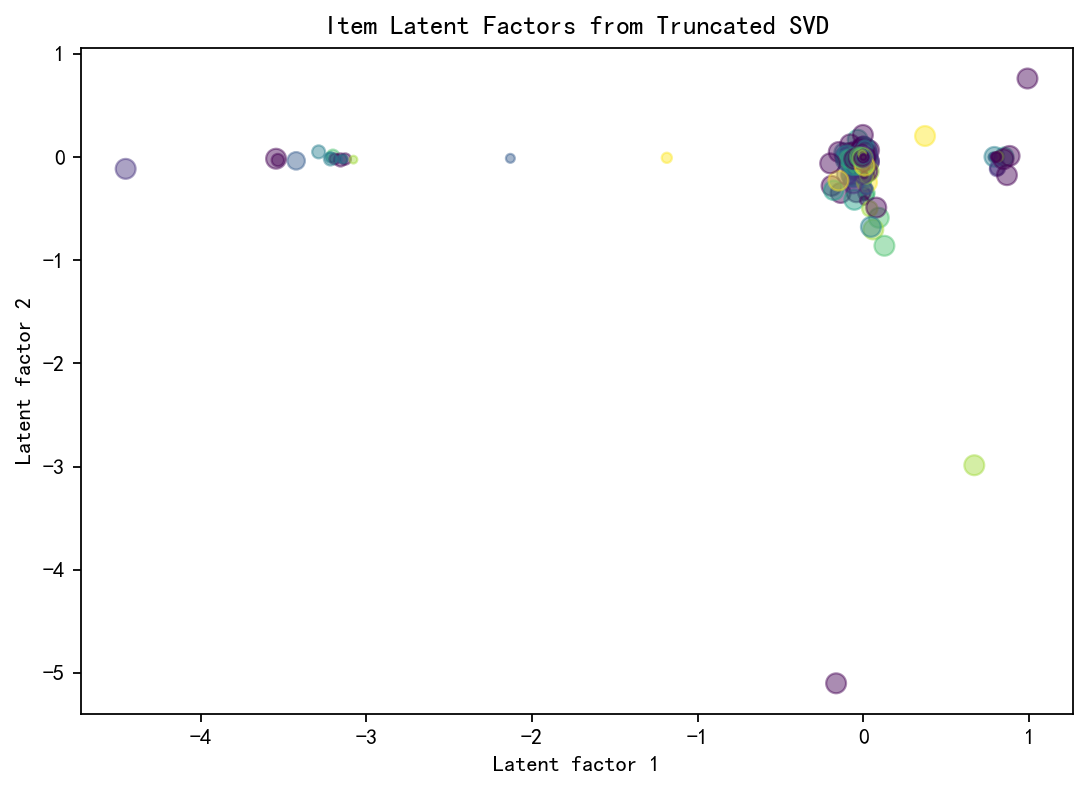

SVD explained variance ratio: [0.00198778 0.00165538]


In [69]:
#30. SVD Item Latent Factor Visualization

# Build the user-item interaction matrix
n_users = int(model_df["user_idx"].max()) + 1
n_items = int(model_df["item_idx"].max()) + 1

centered_rating = model_df["Rating"].values - model_df["Rating"].mean()

mat = sp.csr_matrix(
    (centered_rating, (model_df["user_idx"].values, model_df["item_idx"].values)),
    shape=(n_users, n_items),
)

# Apply Truncated SVD to extract item latent factors
svd = TruncatedSVD(n_components=2, random_state=RANDOM_STATE)
item_factors_2d = svd.fit_transform(mat.T)

# Build item metadata
item_meta = model_df.groupby("item_idx").agg(
    ProductType=("ProductType", "first"),
    interactions=("Rating", "size"),
    avg_rating=("Rating", "mean"),
)

item_meta["svd1"] = item_factors_2d[item_meta.index, 0]
item_meta["svd2"] = item_factors_2d[item_meta.index, 1]

# Select the top 8 product types
top_types = model_df["ProductType"].value_counts().head(8).index

item_plot = item_meta[item_meta["ProductType"].isin(top_types)].sample(
    min(3500, (item_meta["ProductType"].isin(top_types)).sum()),
    random_state=RANDOM_STATE,
)

color_map = {ptype: i for i, ptype in enumerate(top_types)}
colors = item_plot["ProductType"].map(color_map)

# Visualize item latent factors
plt.figure(figsize=(8.0, 5.4))
plt.scatter(
    item_plot["svd1"],
    item_plot["svd2"],
    c=colors,
    s=np.clip(item_plot["interactions"], 8, 80),
    alpha=0.45,
)
plt.title("Item Latent Factors from Truncated SVD")
plt.xlabel("Latent factor 1")
plt.ylabel("Latent factor 2")
plt.show()

print("SVD explained variance ratio:", svd.explained_variance_ratio_)

In [70]:
#31. IQR Outlier Detection

# Detect items with unusually high interaction counts
item_counts = model_df["ProductId"].value_counts()

q1, q3 = item_counts.quantile([0.25, 0.75])
iqr = q3 - q1
item_upper = q3 + 1.5 * iqr

abnormal_items = item_counts[item_counts > item_upper]

# Detect users with unusually high interaction counts
user_counts = model_df["UserId"].value_counts()

uq1, uq3 = user_counts.quantile([0.25, 0.75])
uiqr = uq3 - uq1
user_upper = uq3 + 1.5 * uiqr

abnormal_users = user_counts[user_counts > user_upper]

# Summarize outlier detection results
print("IQR Outlier Detection Results")
print("-" * 40)
print(f"Abnormal items: {len(abnormal_items):,}")
print(f"Abnormal users: {len(abnormal_users):,}")
print(f"Item interaction upper bound: {item_upper:.2f}")
print(f"User interaction upper bound: {user_upper:.2f}")

IQR Outlier Detection Results
----------------------------------------
Abnormal items: 2,245
Abnormal users: 7,816
Item interaction upper bound: 38.50
User interaction upper bound: 7.00


In [71]:
#32. User Cluster Summary

# Summarize user characteristics by cluster
cluster_summary = user_features.groupby("cluster").agg(
    users=("rating_count", "size"),
    avg_interactions=("rating_count", "mean"),
    avg_rating=("avg_rating", "mean"),
    avg_category_diversity=("category_diversity", "mean"),
    avg_active_span_days=("active_span_days", "mean"),
)

# Collect analysis results
advanced_analysis_results = {
    "cluster_summary": cluster_summary,
    "pca_explained": pca.explained_variance_ratio_.tolist(),
    "svd_explained": svd.explained_variance_ratio_.tolist(),
    "abnormal_items": int(len(abnormal_items)),
    "abnormal_users": int(len(abnormal_users)),
    "item_upper": float(item_upper),
    "user_upper": float(user_upper),
}

print("User Cluster Summary")
display(cluster_summary)

print("\nPCA Explained Variance Ratio:")
print(advanced_analysis_results["pca_explained"])

print("\nSVD Explained Variance Ratio:")
print(advanced_analysis_results["svd_explained"])

User Cluster Summary


,users,avg_interactions,avg_rating,avg_category_diversity,avg_active_span_days
cluster,,,,,
0,5762,2.771086,4.690501,2.354217,352.473620
1,8753,1.198675,4.765671,1.141209,0.104878
2,5191,3.991716,3.626762,3.086303,470.521865
3,2443,1.154318,2.164961,1.108064,15.613590



PCA Explained Variance Ratio:
[0.5676048258351264, 0.23599200521042699]

SVD Explained Variance Ratio:
[0.001987775322049856, 0.0016553839668631554]


In [74]:
#33. OLS Regression Statistical Summary

def ols_summary(X: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """
    Calculate OLS regression coefficients and statistical significance.
    """
    Xn = X.astype(float).to_numpy()
    yn = y.astype(float).to_numpy()

    X_design = np.column_stack([np.ones(len(Xn)), Xn])

    beta, *_ = np.linalg.lstsq(X_design, yn, rcond=None)

    residual = yn - X_design @ beta

    n, p = X_design.shape
    dof = max(n - p, 1)

    sigma2 = float((residual @ residual) / dof)

    xtx_inv = np.linalg.pinv(X_design.T @ X_design)
    se = np.sqrt(np.diag(xtx_inv) * sigma2)

    t_values = beta / np.where(se == 0, np.nan, se)
    p_values = 2 * (1 - stats.t.cdf(np.abs(t_values), df=dof))

    names = ["const"] + X.columns.tolist()

    return pd.DataFrame({
        "Variable": names,
        "Coefficient": beta,
        "Standard Error": se,
        "t-statistic": t_values,
        "p-value": p_values,
    })


print("OLS regression function defined successfully.")

OLS regression function defined successfully.


In [75]:
#34. Hypothesis Testing (H1, H2 & H3)

# H1: T-test between popular and long-tail items
item_full_counts = model_df["ProductId"].value_counts()

item_q25, item_q75 = item_full_counts.quantile([0.25, 0.75])

low_items = item_full_counts[item_full_counts <= item_q25].index
high_items = item_full_counts[item_full_counts >= item_q75].index

low_rating = model_df.loc[
    model_df["ProductId"].isin(low_items), "Rating"
].astype(float)

high_rating = model_df.loc[
    model_df["ProductId"].isin(high_items), "Rating"
].astype(float)

h1 = stats.ttest_ind(
    high_rating,
    low_rating,
    equal_var=False,
)

# H2: T-test between low-activity and high-activity users
user_full_counts = model_df["UserId"].value_counts()

user_q25, user_q75 = user_full_counts.quantile([0.25, 0.75])

low_users = user_full_counts[
    user_full_counts <= user_q25
].index

high_users = user_full_counts[
    user_full_counts >= user_q75
].index

low_user_rating = model_df.loc[
    model_df["UserId"].isin(low_users), "Rating"
].astype(float)

high_user_rating = model_df.loc[
    model_df["UserId"].isin(high_users), "Rating"
].astype(float)

h2 = stats.ttest_ind(
    high_user_rating,
    low_user_rating,
    equal_var=False,
)

# H3: One-way ANOVA across the top 8 product categories
top_types = model_df["ProductType"].value_counts().head(8).index.tolist()

category_samples = [
    model_df.loc[
        model_df["ProductType"] == category, "Rating"
    ].values
    for category in top_types
]

h3 = stats.f_oneway(*category_samples)

# Display hypothesis testing results
hypothesis_results = pd.DataFrame({
    "Hypothesis": ["H1: Popular vs. Long-tail Items",
                   "H2: High vs. Low Activity Users",
                   "H3: Differences Across Product Categories"],
    "Test Statistic": [
        h1.statistic,
        h2.statistic,
        h3.statistic,
    ],
    "P-value": [
        h1.pvalue,
        h2.pvalue,
        h3.pvalue,
    ],
})

display(hypothesis_results)

print("H1 - Popular Item Mean Rating:", round(high_rating.mean(), 4))
print("H1 - Long-tail Item Mean Rating:", round(low_rating.mean(), 4))

print("H2 - High-activity User Mean Rating:", round(high_user_rating.mean(), 4))
print("H2 - Low-activity User Mean Rating:", round(low_user_rating.mean(), 4))

print("H3 - Product Categories:", top_types)

,Hypothesis,Test Statistic,P-value
0,H1: Popular vs. Long-tail Items,-2.874508,4.049421e-03
1,H2: High vs. Low Activity Users,-5.428647,5.683861e-08
2,H3: Differences Across Product Categories,26.002230,7.466345e-36


H1 - Popular Item Mean Rating: 4.1837
H1 - Long-tail Item Mean Rating: 4.2072
H2 - High-activity User Mean Rating: 4.1758
H2 - Low-activity User Mean Rating: 4.1997
H3 - Product Categories: ['Nail Polish', 'Shower Gel', 'Sunscreen', 'Shampoo', 'Face Wash & Cleansers', 'Hair Color & Heena', 'Face Serum', 'Body Lotion']


In [77]:
#35. OLS Regression Analysis

# Draw a reproducible sample for regression analysis
sample_for_reg = feature_df.sample(
    min(70000, len(feature_df)),
    random_state=RANDOM_STATE,
)

# Define regression features
reg_cols = [
    "user_train_count_log",
    "user_avg_rating",
    "item_train_count_log",
    "item_avg_rating",
    "category_avg_rating",
    "type_idx",
    "month",
]

# Fit OLS regression
ols = ols_summary(
    sample_for_reg[reg_cols],
    sample_for_reg["Rating"],
)

# Display regression results
display(ols)

,Variable,Coefficient,Standard Error,t-statistic,p-value
0,const,0.570497,0.348425,1.637357,1.015604e-01
1,user_train_count_log,-0.028898,0.005020,-5.756004,8.648690e-09
2,user_avg_rating,0.247850,0.006216,39.875915,0.000000e+00
3,item_train_count_log,-0.010353,0.003291,-3.146122,1.655205e-03
4,item_avg_rating,0.376542,0.007929,47.490140,0.000000e+00
5,category_avg_rating,0.246066,0.083298,2.954036,3.137517e-03
6,type_idx,0.002303,0.001039,2.215937,2.669900e-02
7,month,-0.002195,0.001318,-1.665135,9.589028e-02


In [79]:
#36. Moderation Effect Analysis

# Create a copy of the regression sample
mod_sample = sample_for_reg.copy()

# Standardize variables for interaction analysis
for col in [
    "user_avg_rating",
    "item_train_count_log",
    "item_avg_rating",
    "category_avg_rating",
]:
    mod_sample[col + "_z"] = (
        (mod_sample[col] - mod_sample[col].mean())
        / (mod_sample[col].std() + 1e-9)
    )

# Construct the interaction term
mod_sample["user_avg_x_item_pop"] = (
    mod_sample["user_avg_rating_z"]
    * mod_sample["item_train_count_log_z"]
)

# Define moderation regression features
moderation_cols = [
    "user_avg_rating_z",
    "item_train_count_log_z",
    "item_avg_rating_z",
    "category_avg_rating_z",
    "user_avg_x_item_pop",
]

# Fit moderation regression
moderation = ols_summary(
    mod_sample[moderation_cols],
    mod_sample["Rating"],
)

# Display moderation results
display(moderation)

,Variable,Coefficient,Standard Error,t-statistic,p-value
0,const,4.190253,0.004476,936.253086,0.000000
1,user_avg_rating_z,0.178357,0.004478,39.827796,0.000000
2,item_train_count_log_z,-0.017634,0.004479,-3.936751,0.000083
3,item_avg_rating_z,0.213577,0.004489,47.579908,0.000000
4,category_avg_rating_z,0.012322,0.004485,2.747088,0.006014
5,user_avg_x_item_pop,0.011546,0.004508,2.561240,0.010432


In [80]:
#37. Logistic Regression and Odds Ratio Analysis

# Prepare the classification sample
clf_sample = sample_for_reg.copy()

# Define the binary target variable
y_bin = (clf_sample["Rating"] >= 4).astype(int)

# Standardize regression features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    clf_sample[reg_cols]
)

# Fit logistic regression
logit = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
)

logit.fit(X_scaled, y_bin)

# Calculate standardized coefficients and odds ratios
logit_table = pd.DataFrame({
    "Variable": reg_cols,
    "Standardized Coefficient": logit.coef_[0],
    "Odds Ratio": np.exp(logit.coef_[0]),
}).sort_values(
    "Standardized Coefficient",
    ascending=False,
)

# Display logistic regression results
display(logit_table)

,Variable,Standardized Coefficient,Odds Ratio
3,item_avg_rating,0.344435,1.411192
1,user_avg_rating,0.275865,1.317671
4,category_avg_rating,0.027352,1.027729
5,type_idx,0.008702,1.008740
6,month,-0.014896,0.985215
0,user_train_count_log,-0.032267,0.968248
2,item_train_count_log,-0.033031,0.967509


In [81]:
#38. Diagnostic Analysis Results Summary

diagnostic_results = {
    "h1": {
        "high_mean": float(high_rating.mean()),
        "low_mean": float(low_rating.mean()),
        "t": float(h1.statistic),
        "p": float(h1.pvalue),
    },
    "h2": {
        "high_mean": float(high_user_rating.mean()),
        "low_mean": float(low_user_rating.mean()),
        "t": float(h2.statistic),
        "p": float(h2.pvalue),
    },
    "h3": {
        "f": float(h3.statistic),
        "p": float(h3.pvalue),
        "top_types": top_types,
    },
    "ols": ols,
    "moderation": moderation,
    "logit_table": logit_table,
}

print("Diagnostic analysis completed successfully.")

print("\nH1 - Popular vs. Long-tail Items")
print(diagnostic_results["h1"])

print("\nH2 - High vs. Low Activity Users")
print(diagnostic_results["h2"])

print("\nH3 - Product Category ANOVA")
print(diagnostic_results["h3"])

Diagnostic analysis completed successfully.

H1 - Popular vs. Long-tail Items
{'high_mean': 4.18372357929376, 'low_mean': 4.2072086251672305, 't': -2.8745082726602456, 'p': 0.004049421223268176}

H2 - High vs. Low Activity Users
{'high_mean': 4.17576085643602, 'low_mean': 4.199737616150812, 't': -5.42864744724952, 'p': 5.683860706511424e-08}

H3 - Product Category ANOVA
{'f': 26.002229690551758, 'p': 7.466344936803765e-36, 'top_types': ['Nail Polish', 'Shower Gel', 'Sunscreen', 'Shampoo', 'Face Wash & Cleansers', 'Hair Color & Heena', 'Face Serum', 'Body Lotion']}


In [82]:
#39. Train, Validation and Test Array Preparation

def split_feature_arrays(feature_df: pd.DataFrame, feature_names: List[str]):
    train = feature_df[feature_df["split"] == "train"].copy()
    val = feature_df[feature_df["split"] == "val"].copy()
    test = feature_df[feature_df["split"] == "test"].copy()

    X_train = train[feature_names].astype(float)
    X_val = val[feature_names].astype(float)
    X_test = test[feature_names].astype(float)

    y_train = train["Rating"].values
    y_val = val["Rating"].values
    y_test = test["Rating"].values

    return (
        train, val, test,
        X_train, X_val, X_test,
        y_train, y_val, y_test
    )

In [83]:
#40. Baseline Prediction and Model Evaluation

def baseline_bias_predict(
    train: pd.DataFrame,
    target: pd.DataFrame,
    global_mean: float
) -> np.ndarray:
    user_mean = train.groupby("UserId")["Rating"].mean()
    item_mean = train.groupby("ProductId")["Rating"].mean()

    pred = (
        global_mean
        + target["UserId"].map(user_mean).fillna(global_mean)
        - global_mean
        + target["ProductId"].map(item_mean).fillna(global_mean)
        - global_mean
    )

    return clip_rating(pred.astype(float))

def evaluate_predictions(
    name: str,
    split: str,
    y_true: np.ndarray,
    pred: np.ndarray
) -> Dict:
    y_bin = (y_true >= 4).astype(int)

    prec, rec = safe_precision_recall(
        y_true_binary=y_bin,
        pred_rating=pred
    )

    return {
        "模型": name,
        "数据集": split,
        "RMSE": rmse(y_true, pred),
        "MAE": float(mean_absolute_error(y_true, pred)),
        "AUC": safe_auc(y_bin, pred),
        "Precision": prec,
        "Recall": rec,
    }

In [84]:
#41. Matrix Factorization Model

class MatrixFactorization:
    def __init__(
        self,
        n_users: int,
        n_items: int,
        n_factors=24,
        lr=0.012,
        reg=0.04,
        epochs=5
    ):
        self.n_users = n_users
        self.n_items = n_items
        self.n_factors = n_factors
        self.lr = lr
        self.reg = reg
        self.epochs = epochs

        rng = np.random.default_rng(RANDOM_STATE)

        self.P = (
            0.05 * rng.standard_normal((n_users, n_factors))
        ).astype("float32")

        self.Q = (
            0.05 * rng.standard_normal((n_items, n_factors))
        ).astype("float32")

        self.bu = np.zeros(n_users, dtype="float32")
        self.bi = np.zeros(n_items, dtype="float32")
        self.global_mean = 0.0

    def fit(self, users, items, ratings):
        self.global_mean = float(np.mean(ratings))

        indices = np.arange(len(ratings))
        rng = np.random.default_rng(RANDOM_STATE)

        for _ in range(self.epochs):
            rng.shuffle(indices)

            for idx in indices:
                u = int(users[idx])
                i = int(items[idx])
                r = float(ratings[idx])

                pred = (
                    self.global_mean
                    + self.bu[u]
                    + self.bi[i]
                    + self.P[u] @ self.Q[i]
                )

                err = r - pred

                self.bu[u] += self.lr * (
                    err - self.reg * self.bu[u]
                )

                self.bi[i] += self.lr * (
                    err - self.reg * self.bi[i]
                )

                pu = self.P[u].copy()
                qi = self.Q[i].copy()

                self.P[u] += self.lr * (
                    err * qi - self.reg * pu
                )

                self.Q[i] += self.lr * (
                    err * pu - self.reg * qi
                )

        return self

    def predict(self, users: np.ndarray, items: np.ndarray):
        pred = (
            self.global_mean
            + self.bu[users]
            + self.bi[items]
            + np.sum(self.P[users] * self.Q[items], axis=1)
        )

        return clip_rating(pred)

In [85]:
#42. NeuMF Neural Collaborative Filtering Architecture

if TORCH_AVAILABLE:
    class NeuMF(nn.Module):
        def __init__(self, n_users, n_items, emb_dim=16):
            super().__init__()

            self.user_gmf = nn.Embedding(n_users, emb_dim)
            self.item_gmf = nn.Embedding(n_items, emb_dim)

            self.user_mlp = nn.Embedding(n_users, emb_dim)
            self.item_mlp = nn.Embedding(n_items, emb_dim)

            self.mlp = nn.Sequential(
                nn.Linear(emb_dim * 2, 64),
                nn.ReLU(),
                nn.Dropout(0.08),
                nn.Linear(64, 32),
                nn.ReLU(),
            )

            self.out = nn.Linear(emb_dim + 32, 1)

        def forward(self, u, i):
            gmf = self.user_gmf(u) * self.item_gmf(i)

            mlp_input = torch.cat(
                [self.user_mlp(u), self.item_mlp(i)],
                dim=1
            )

            mlp_out = self.mlp(mlp_input)

            score = self.out(
                torch.cat([gmf, mlp_out], dim=1)
            ).squeeze(1)

            return 1 + 4 * torch.sigmoid(score)

In [86]:
#43. NeuMF Model Training and Prediction

def train_neumf(train, n_users, n_items, epochs=1):
    if TORCH_AVAILABLE:
        device = torch.device("cpu")

        model = NeuMF(
            n_users,
            n_items,
            emb_dim=16
        ).to(device)

        opt = torch.optim.Adam(
            model.parameters(),
            lr=0.003,
            weight_decay=1e-5
        )

        train_sample = train.sample(
            min(len(train), 10000),
            random_state=RANDOM_STATE
        )

        users_t = torch.tensor(
            train_sample["user_idx"].values,
            dtype=torch.long,
            device=device
        )

        items_t = torch.tensor(
            train_sample["item_idx"].values,
            dtype=torch.long,
            device=device
        )

        ratings_t = torch.tensor(
            train_sample["Rating"].values,
            dtype=torch.float32,
            device=device
        )

        batch_size = 4096
        loss_fn = nn.MSELoss()

        model.train()

        for _ in range(epochs):
            for start in range(0, len(train_sample), batch_size):
                end = start + batch_size

                opt.zero_grad()

                pred = model(
                    users_t[start:end],
                    items_t[start:end]
                )

                loss = loss_fn(
                    pred,
                    ratings_t[start:end]
                )

                loss.backward()
                opt.step()

        return {
            "kind": "torch",
            "model": model,
            "n_users": n_users,
            "n_items": n_items
        }

    else:
        train_sample = train.sample(
            min(len(train), 12000),
            random_state=RANDOM_STATE
        )

        X = np.column_stack([
            train_sample["user_idx"] / max(n_users, 1),
            train_sample["item_idx"] / max(n_items, 1)
        ])

        y = train_sample["Rating"].values

        mlp = MLPRegressor(
            hidden_layer_sizes=(32, 16),
            max_iter=35,
            random_state=RANDOM_STATE
        )

        mlp.fit(X, y)

        return {
            "kind": "mlp",
            "model": mlp,
            "n_users": n_users,
            "n_items": n_items
        }


def predict_neumf(model, users, items):
    if model.get("kind") == "torch":
        torch_model = model["model"]
        torch_model.eval()

        res_list = []

        with torch.no_grad():
            for s in range(0, len(users), 16384):
                u_batch = torch.tensor(
                    users[s:s + 16384],
                    dtype=torch.long
                )

                i_batch = torch.tensor(
                    items[s:s + 16384],
                    dtype=torch.long
                )

                res_list.append(
                    torch_model(u_batch, i_batch).cpu().numpy()
                )

        return clip_rating(np.concatenate(res_list))

    else:
        X = np.column_stack([
            users / max(model["n_users"], 1),
            items / max(model["n_items"], 1)
        ])

        return clip_rating(model["model"].predict(X))

In [87]:
#44. Top-K Recommendation Ranking Metrics

def ranking_metrics(
    name,
    train,
    test,
    n_items,
    predict_func,
    k=10,
    max_users=40
):
    rng = np.random.default_rng(RANDOM_STATE)

    train_user_item = (
        train.groupby("user_idx")["item_idx"]
        .apply(set)
        .to_dict()
    )

    test_pos = (
        test[test["Rating"] >= 4]
        .groupby("user_idx")["item_idx"]
        .apply(list)
        .to_dict()
    )

    candidate_users = [
        u for u in test_pos
        if u in train_user_item and len(test_pos[u]) > 0
    ]

    rng.shuffle(candidate_users)
    candidate_users = candidate_users[:max_users]

    all_item_ids = np.arange(n_items)

    recall_list = []
    ndcg_list = []
    hit_list = []

    for u in candidate_users:
        pos_items = list(dict.fromkeys(test_pos[u]))

        seen = train_user_item[u] | set(pos_items)

        neg_candidates = np.setdiff1d(
            all_item_ids,
            list(seen)
        )

        if len(neg_candidates) == 0:
            continue

        neg_sample_size = min(40, len(neg_candidates))

        neg_sample = rng.choice(
            neg_candidates,
            size=neg_sample_size,
            replace=False
        )

        all_cand = np.array(pos_items + neg_sample)

        pred_score = predict_func(
            np.full(len(all_cand), u),
            all_cand
        )

        sort_idx = np.argsort(pred_score)[::-1][:k]
        top_items = all_cand[sort_idx]

        hit_num = sum(
            1 for x in top_items
            if x in pos_items
        )

        recall = hit_num / min(k, len(pos_items))

        dcg = sum(
            1 / math.log2(idx + 2)
            for idx, val in enumerate(top_items)
            if val in pos_items
        )

        idcg = sum(
            1 / math.log2(i + 2)
            for i in range(min(k, len(pos_items)))
        )

        recall_list.append(recall)
        ndcg_list.append(dcg / idcg if idcg > 0 else 0)
        hit_list.append(1 if hit_num > 0 else 0)

    return {
        "模型": name,
        "K": k,
        "Recall@K": float(np.mean(recall_list)) if recall_list else np.nan,
        "NDCG@K": float(np.mean(ndcg_list)) if ndcg_list else np.nan,
        "HitRate@K": float(np.mean(hit_list)) if hit_list else np.nan
    }

In [88]:
#45. Predictive Model Training and Performance Comparison

def train_predictive_models(feature_df, store, model_df):
    (
        train, val, test,
        X_train, X_val, X_test,
        y_train, y_val, y_test
    ) = split_feature_arrays(
        feature_df,
        store.feature_names
    )

    eval_res = []

    # Baseline Model
    base_pred_val = baseline_bias_predict(
        train,
        val,
        store.global_mean
    )

    base_pred_test = baseline_bias_predict(
        train,
        test,
        store.global_mean
    )

    eval_res.append(
        evaluate_predictions(
            "均值基线",
            "验证集",
            y_val,
            base_pred_val
        )
    )

    eval_res.append(
        evaluate_predictions(
            "均值基线",
            "测试集",
            y_test,
            base_pred_test
        )
    )

    # Random Forest
    fit_size = min(40000, len(X_train))

    fit_idx = np.random.choice(
        len(X_train),
        size=fit_size,
        replace=False
    )

    X_fit = X_train.iloc[fit_idx]
    y_fit = y_train[fit_idx]

    rf = RandomForestRegressor(
        n_estimators=15,
        max_depth=8,
        random_state=RANDOM_STATE
    )

    rf.fit(X_fit, y_fit)

    rf_val_pred = clip_rating(rf.predict(X_val))
    rf_test_pred = clip_rating(rf.predict(X_test))

    eval_res.append(
        evaluate_predictions(
            "随机森林",
            "验证集",
            y_val,
            rf_val_pred
        )
    )

    eval_res.append(
        evaluate_predictions(
            "随机森林",
            "测试集",
            y_test,
            rf_test_pred
        )
    )

    # XGBoost
    xgb_model = XGBRegressor(
        max_depth=4,
        learning_rate=0.08,
        random_state=RANDOM_STATE
    )

    xgb_model.fit(
        X_fit,
        y_fit,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    xgb_val_pred = clip_rating(
        xgb_model.predict(X_val)
    )

    xgb_test_pred = clip_rating(
        xgb_model.predict(X_test)
    )

    eval_res.append(
        evaluate_predictions(
            "XGBoost",
            "验证集",
            y_val,
            xgb_val_pred
        )
    )

    eval_res.append(
        evaluate_predictions(
            "XGBoost",
            "测试集",
            y_test,
            xgb_test_pred
        )
    )

    # Matrix Factorization Collaborative Filtering
    n_user = model_df["user_idx"].max() + 1
    n_item = model_df["item_idx"].max() + 1

    mf = MatrixFactorization(
        n_user,
        n_item
    )

    mf.fit(
        train["user_idx"].values,
        train["item_idx"].values,
        y_train
    )

    mf_val_pred = mf.predict(
        val["user_idx"].values,
        val["item_idx"].values
    )

    mf_test_pred = mf.predict(
        test["user_idx"].values,
        test["item_idx"].values
    )

    eval_res.append(
        evaluate_predictions(
            "矩阵分解协同过滤",
            "验证集",
            y_val,
            mf_val_pred
        )
    )

    eval_res.append(
        evaluate_predictions(
            "矩阵分解协同过滤",
            "测试集",
            y_test,
            mf_test_pred
        )
    )

    # NeuMF
    neumf_model = train_neumf(
        train,
        n_user,
        n_item
    )

    neumf_val_pred = predict_neumf(
        neumf_model,
        val["user_idx"].values,
        val["item_idx"].values
    )

    neumf_test_pred = predict_neumf(
        neumf_model,
        test["user_idx"].values,
        test["item_idx"].values
    )

    eval_res.append(
        evaluate_predictions(
            "NeuMF",
            "验证集",
            y_val,
            neumf_val_pred
        )
    )

    eval_res.append(
        evaluate_predictions(
            "NeuMF",
            "测试集",
            y_test,
            neumf_test_pred
        )
    )

    # Feature Importance Visualization
    feat_import = pd.DataFrame({
        "特征名": store.feature_names,
        "RF重要性": rf.feature_importances_,
        "XGB重要性": xgb_model.feature_importances_
    }).sort_values(
        "XGB重要性",
        ascending=False
    )

    plt.figure()

    top10 = feat_import.head(10).sort_values(
        "XGB重要性"
    )

    plt.barh(
        top10["特征名"],
        top10["XGB重要性"]
    )

    plt.title("XGBoost特征重要性")
    plt.show()

    return {
        "eval_result": eval_res,
        "rf": rf,
        "xgb": xgb_model,
        "mf": mf,
        "neumf": neumf_model,
        "train": train,
        "test": test,
        "xgb_test_pred": xgb_test_pred
    }

In [95]:
#46. Prescriptive Optimization and Sensitivity Analysis

def prescriptive_optimization(model_df, store, pred_result):
    train = model_df[model_df["split"] == "train"].copy()

    item_stat = train.groupby("ProductId").agg(
        item_count=("Rating", "size"),
        avg_score=("Rating", "mean"),
        ProductType=("ProductType", "first")
    )

    top_item = item_stat.sort_values(
        "item_count",
        ascending=False
    ).head(180)

    active_user = (
        train["UserId"]
        .value_counts()
        .head(15)
        .index
        .tolist()
    )

    latest_day = model_df["date"].max()

    user_history = (
        train.groupby("UserId")["ProductId"]
        .apply(set)
        .to_dict()
    )

    # Generate candidate records for all active users
    candidate_rows = []

    for user in active_user:
        seen_pid = user_history.get(user, set())

        cand_pid = top_item[
            ~top_item.index.isin(seen_pid)
        ].head(40)

        if len(cand_pid) < 20:
            cand_pid = top_item.head(40)

        for pid, row in cand_pid.iterrows():
            candidate_rows.append({
                "UserId": user,
                "ProductId": pid,
                "ProductType": row["ProductType"],
                "item_count": row["item_count"],
                "avg_score": row["avg_score"]
            })

    candidate_raw = pd.DataFrame(candidate_rows)

    candidate_raw["candidate_id"] = np.arange(
        len(candidate_raw)
    )

    # Prepare candidate feature input
    candidate_input = candidate_raw[
        ["UserId", "ProductId", "ProductType", "candidate_id"]
    ].copy()

    candidate_input["Rating"] = np.nan
    candidate_input["date"] = latest_day
    candidate_input["year"] = latest_day.year
    candidate_input["month"] = latest_day.month
    candidate_input["quarter"] = (
        (latest_day.month - 1) // 3
    ) + 1
    candidate_input["split"] = "candidate"
    candidate_input["user_idx"] = 0
    candidate_input["item_idx"] = 0

    # Combine training history and candidates for feature generation
    combined_df = pd.concat(
        [model_df, candidate_input],
        ignore_index=True,
        sort=False
    )

    combined_features = apply_features(
        combined_df,
        store
    )

    # Extract candidate features only
    candidate_features = combined_features[
        combined_features["split"] == "candidate"
    ].copy()

    candidate_features = candidate_features.sort_values(
        "candidate_id"
    )

    candidate_raw = candidate_raw.sort_values(
        "candidate_id"
    ).reset_index(drop=True)

    candidate_features = candidate_features.reset_index(
        drop=True
    )

    # Predict candidate ratings using XGBoost
    candidate_raw["pred_score"] = clip_rating(
        pred_result["xgb"].predict(
            candidate_features[store.feature_names]
        )
    )

    # Select top 25 candidates for each user
    candidate_all = []

    for user, user_cand in candidate_raw.groupby("UserId"):
        user_cand = user_cand.sort_values(
            "pred_score",
            ascending=False
        ).head(25).copy()

        candidate_all.append(user_cand)

    candidates = pd.concat(
        candidate_all,
        ignore_index=True
    )

    candidates["var_idx"] = np.arange(
        len(candidates)
    )

    candidates["is_longtail"] = (
        candidates["item_count"]
        <= candidates["item_count"].median()
    ).astype(int)

    def solve_milp(k, exp_cap):
        n_var = len(candidates)

        c = -candidates["pred_score"].values

        constraints = []
        lb, ub = [], []

        # Each user receives exactly K recommendations
        for user, group_idx in candidates.groupby("UserId")["var_idx"]:
            mat = sp.lil_matrix((1, n_var))
            mat[0, group_idx.values] = 1

            constraints.append(mat.tocsr())
            lb.append(k)
            ub.append(k)

        # Maximum exposure for each item
        for pid, group_idx in candidates.groupby("ProductId")["var_idx"]:
            mat = sp.lil_matrix((1, n_var))
            mat[0, group_idx.values] = 1

            constraints.append(mat.tocsr())
            lb.append(0)
            ub.append(exp_cap)

        # At most three recommendations from each category per user
        for (user, product_type), idx_arr in candidates.groupby(
            ["UserId", "ProductType"]
        )["var_idx"]:
            mat = sp.lil_matrix((1, n_var))
            mat[0, idx_arr.values] = 1

            constraints.append(mat.tocsr())
            lb.append(0)
            ub.append(3)

        # At least one long-tail item for each user
        for user, sub in candidates.groupby("UserId"):
            long_idx = sub[
                sub["is_longtail"] == 1
            ]["var_idx"].values

            if len(long_idx) == 0:
                continue

            mat = sp.lil_matrix((1, n_var))
            mat[0, long_idx] = 1

            constraints.append(mat.tocsr())
            lb.append(1)
            ub.append(k)

        A = sp.vstack(constraints).tocsr()

        cons = LinearConstraint(
            A,
            np.array(lb),
            np.array(ub)
        )

        res = milp(
            c=c,
            integrality=np.ones(n_var),
            bounds=Bounds(0, 1),
            constraints=cons,
            options={"time_limit": 45}
        )

        out_df = candidates.copy()

        if res.success:
            out_df["selected"] = (
                res.x >= 0.5
            ).astype(int)

        else:
            out_df["selected"] = 0

            for user, sub in out_df.groupby("UserId"):
                topk = (
                    sub.sort_values(
                        "pred_score",
                        ascending=False
                    )
                    .head(k)
                    .index
                )

                out_df.loc[topk, "selected"] = 1

        return res, out_df

    # Default Optimization
    K_DEFAULT = 8
    CAP_DEFAULT = 8

    milp_result, opt_df = solve_milp(
        K_DEFAULT,
        CAP_DEFAULT
    )

    # Sensitivity Analysis
    sen_result = []

    for k_param in [4, 6, 8, 10, 12]:
        cap_param = max(
            4,
            int(np.ceil(
                len(active_user) * k_param * 0.025
            ))
        )

        _, sen_solution = solve_milp(
            k_param,
            cap_param
        )

        select_df = sen_solution[
            sen_solution["selected"] == 1
        ]

        sen_result.append({
            "推荐位K": k_param,
            "曝光上限": cap_param,
            "平均预测分": (
                float(select_df["pred_score"].mean())
                if len(select_df) > 0 else np.nan
            ),
            "唯一商品数": int(
                select_df["ProductId"].nunique()
            )
        })

    sensitivity_df = pd.DataFrame(sen_result)

    # Sensitivity Analysis Visualization
    fig, ax1 = plt.subplots(figsize=(7.8, 4.6))

    ax1.plot(
        sensitivity_df["推荐位K"],
        sensitivity_df["平均预测分"],
        marker="o"
    )

    ax2 = ax1.twinx()

    ax2.plot(
        sensitivity_df["推荐位K"],
        sensitivity_df["唯一商品数"],
        marker="s",
        color="r"
    )

    plt.title("参数敏感性：推荐位K与评分/商品覆盖关系")
    plt.show()

    return {
        "milp_solve_result": milp_result,
        "opt_solution_df": opt_df,
        "sensitivity_data": sensitivity_df,
        "default_K": K_DEFAULT,
        "default_exposure": CAP_DEFAULT
    }

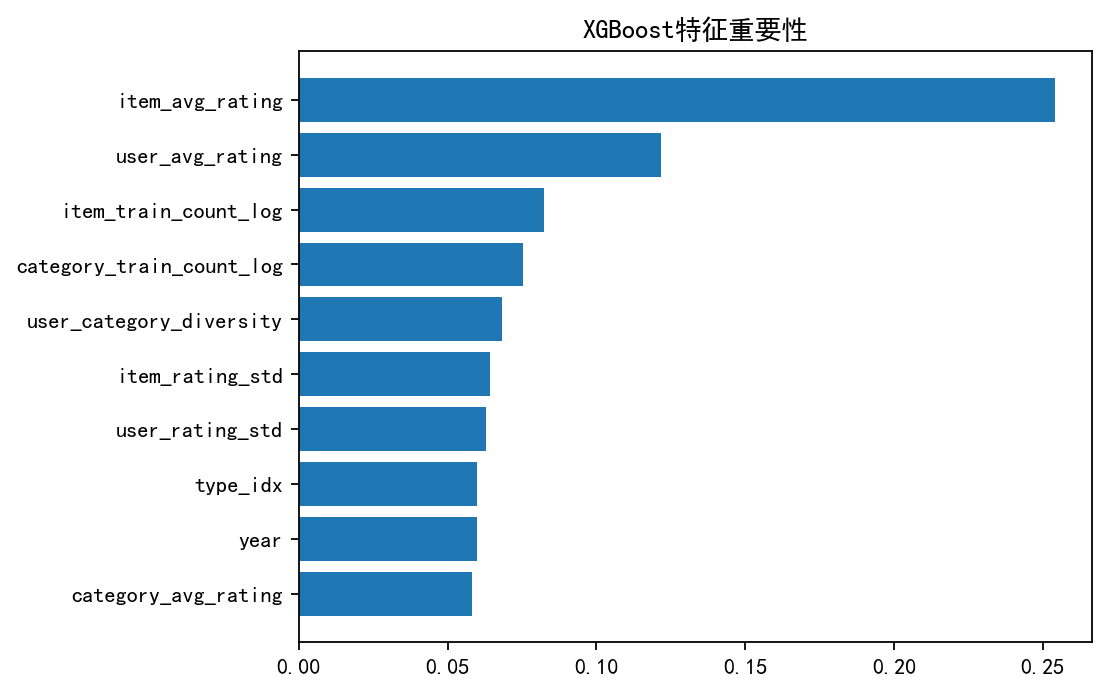

Predictive modeling completed successfully!


In [97]:
#47. Main Analysis Pipeline Execution

# 1. Load Raw Data
df_raw = load_data()

# 2. Generate Dataset Overview
data_overview = full_data_profile(df_raw)

# 3. Build Model Dataset
model_data, split_info = build_model_dataset(df_raw)

# 4. Generate Historical Features
train_set = model_data[model_data["split"] == "train"]
feat_store = make_feature_store(train_set, model_data)
feat_data = apply_features(model_data, feat_store)

# 5. Collect Diagnostic Analysis Results
diag_res = diagnostic_results

# 6. Update Model Feature Names
feat_store.feature_names = [
    "user_train_count_log",
    "user_avg_rating",
    "user_rating_std",
    "user_category_diversity",
    "item_train_count_log",
    "item_avg_rating",
    "item_rating_std",
    "category_train_count_log",
    "category_avg_rating",
    "type_idx",
    "year",
    "month",
    "quarter"
]

# 7. Train Predictive Models
pred_res = train_predictive_models(
    feat_data,
    feat_store,
    model_data
)

print("Predictive modeling completed successfully!")

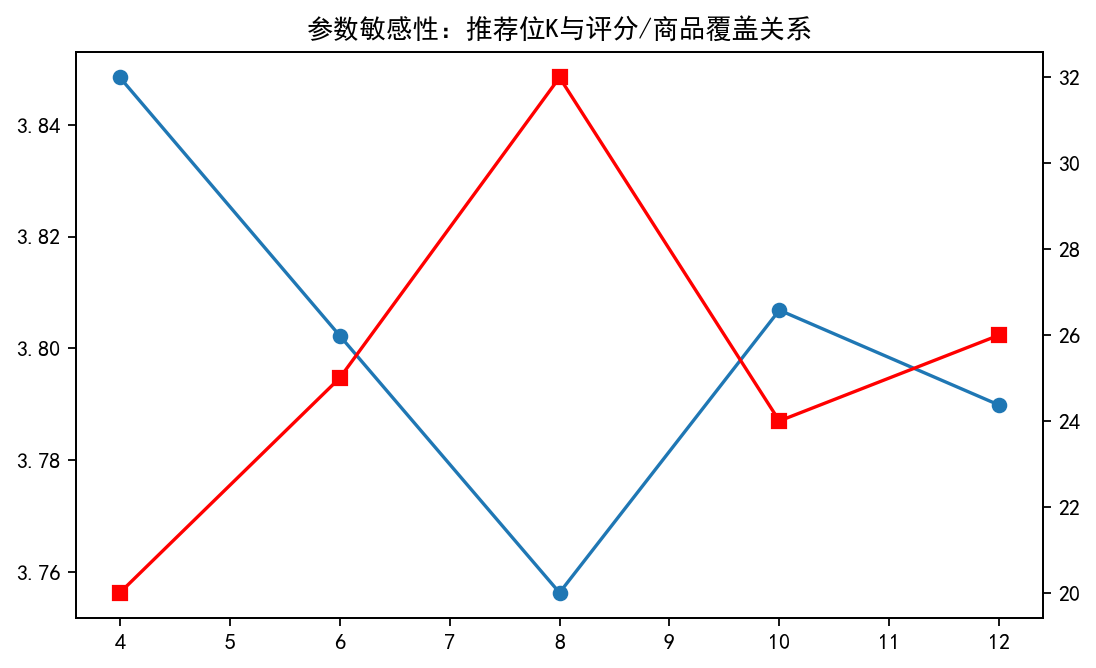

In [96]:
#48. Run Prescriptive Optimization

opt_res = prescriptive_optimization(
    model_data,
    feat_store,
    pred_res
)

In [99]:
#49. Optimization Results and Performance Evaluation

# 1. MILP Optimization Status
print("MILP Optimization Status")
print("-" * 50)
print("Success:", opt_res["milp_solve_result"].success)
print("Message:", opt_res["milp_solve_result"].message)

# 2. Selected Recommendations
selected_recommendations = opt_res["opt_solution_df"].query(
    "selected == 1"
).copy()

print("\nSelected Recommendations")
print("-" * 50)
print("Total recommendations:", len(selected_recommendations))
print("Unique users:", selected_recommendations["UserId"].nunique())
print("Unique products:", selected_recommendations["ProductId"].nunique())

display(selected_recommendations.head(20))

# 3. Sensitivity Analysis Results
print("\nSensitivity Analysis Results")
print("-" * 50)

display(opt_res["sensitivity_data"])

# 4. Recommendation Constraint Evaluation
print("\nRecommendation Constraint Evaluation")
print("-" * 50)

user_counts = selected_recommendations.groupby("UserId").size()
item_exposure = selected_recommendations.groupby("ProductId").size()
category_counts = selected_recommendations.groupby(
    ["UserId", "ProductType"]
).size()

longtail_counts = selected_recommendations.groupby("UserId")[
    "is_longtail"
].sum()

print("Exactly 8 recommendations per user:",
      bool((user_counts == opt_res["default_K"]).all()))

print("Item exposure within the default cap:",
      bool((item_exposure <= opt_res["default_exposure"]).all()))

print("Maximum 3 items per category per user:",
      bool((category_counts <= 3).all()))

print("At least 1 long-tail item per user:",
      bool((longtail_counts >= 1).all()))

print("\nOptimization evaluation completed.")

MILP Optimization Status
--------------------------------------------------
Success: True
Message: Optimization terminated successfully. (HiGHS Status 7: Optimal)

Selected Recommendations
--------------------------------------------------
Total recommendations: 120
Unique users: 15
Unique products: 22


,UserId,ProductId,ProductType,item_count,avg_score,candidate_id,pred_score,var_idx,is_longtail,selected
0,A1ODOGXEYECQQ8,B0043OYFKU,Sunscreen,83,4.216867,322,4.275869,0,0,1
1,A1ODOGXEYECQQ8,B006L1DNWY,Face Serum,55,4.272727,332,4.040528,1,0,1
2,A1ODOGXEYECQQ8,B008U1Q4DI,Conditioner,58,4.448276,331,4.034217,2,0,1
3,A1ODOGXEYECQQ8,B003S516XO,Shampoo,44,4.840909,340,3.995332,3,1,1
4,A1ODOGXEYECQQ8,B0069FDR96,Face Serum,73,4.164383,324,3.989239,4,0,1
5,A1ODOGXEYECQQ8,B00639DLV2,Face Serum,41,4.560976,342,3.958670,5,1,1
6,A1ODOGXEYECQQ8,B002DOO1VA,Face Wash & Cleansers,40,4.325000,345,3.939438,6,1,1
7,A1ODOGXEYECQQ8,B000ZMBSPE,Nail Polish,86,4.430233,320,3.898552,7,0,1
25,A22CW0ZHY3NJH8,B0043OYFKU,Sunscreen,83,4.216867,442,4.262601,25,0,1
26,A22CW0ZHY3NJH8,B006L1DNWY,Face Serum,55,4.272727,452,4.027260,26,0,1



Sensitivity Analysis Results
--------------------------------------------------


,推荐位K,曝光上限,平均预测分,唯一商品数
0,4,4,3.848443,20
1,6,4,3.802280,25
2,8,4,3.756326,32
3,10,4,3.806843,24
4,12,5,3.789865,26



Recommendation Constraint Evaluation
--------------------------------------------------
Exactly 8 recommendations per user: True
Item exposure within the default cap: True
Maximum 3 items per category per user: True
At least 1 long-tail item per user: True

Optimization evaluation completed.
